<a href="https://colab.research.google.com/github/xabierblanch/EGG_FotogrametriaTerrestre/blob/main/FMT_S5_GeometriaEpipolar_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/xabierblanch/EGG_FotogrametriaTerrestre/blob/main/FMT_S5_GeometriaEpipolar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEOMETRIA EPIPOLAR - Exercicis pràctics

Aquest notebook segueix el mateix fil que la teoria:

| Part | Contingut | Dades |
|---|---|---|
| **1** | Visualitzar els conceptes: raig, recta epipolar, pla epipolar i coplanarietat | Escena **simulada** |
| **2** | La matriu fonamental **F**: sistema d'equacions, solució i comprovació | Fotos reals de l'aula |
| **3** | La matriu **K**, la matriu essencial **E** i l'orientació relativa | Simulació i fotos reals |
| **4** | Parelles errònies i **RANSAC** programat a mà | Fotos reals de l'aula |
| **5** | Ampliació: imatges epipolars | Fotos reals de l'aula |

## 0.- Configuració de l'entorn

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from ipywidgets import interact, FloatSlider
from IPython.display import display

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams['figure.figsize'] = [14, 6]
plt.rcParams['figure.dpi'] = 90
np.set_printoptions(precision=4, suppress=True)
RANDOM_SEED = 0


def format_matrix(matrix, digits=3):
    """Scientific notation, useful for matrices with very different magnitudes (such as F)."""
    return np.array2string(np.asarray(matrix), formatter={'float_kind': lambda x: f'{x: .{digits}e}'})


def to_homogeneous(points):
    return np.column_stack([points, np.ones(len(points))])


def line_endpoints(line, width, height):
    """Intersection of the line a·u + b·v + c = 0 with the borders of a width x height image."""
    a, b, c = line
    candidates = []
    if abs(b) > 1e-12:
        candidates += [(0, -c / b), (width - 1, -(c + a * (width - 1)) / b)]
    if abs(a) > 1e-12:
        candidates += [(-c / a, 0), (-(c + b * (height - 1)) / a, height - 1)]
    inside = [(u, v) for u, v in candidates if -1 <= u <= width and -1 <= v <= height]
    return np.array(inside[:2]) if len(inside) >= 2 else None


def pick_spread_points(points, n_points, seed=RANDOM_SEED):
    """Picks n points spread over the image (farthest point sampling)."""
    rng = np.random.default_rng(seed)
    chosen = [int(rng.integers(len(points)))]
    for _ in range(n_points - 1):
        distance_to_chosen = np.min(np.linalg.norm(points[:, None] - points[chosen][None], axis=2), axis=1)
        chosen.append(int(np.argmax(distance_to_chosen)))
    return np.array(chosen)


print("Entorn configurat correctament amb OpenCV", cv2.__version__)

Entorn configurat correctament amb OpenCV 5.0.0


# PART 1 — Visualitzar la geometria epipolar (escena simulada)

En una foto real no podem veure els raigs ni els plans: només tenim píxels. Per **veure** els conceptes de la teoria, en aquesta part **simulem** una aula (uns quants centenars de punts 3D: una paret al fons i unes taules) i **dues càmeres** que la fotografien.

Com que la simulem nosaltres, **ho sabem tot**: on és cada punt 3D i on és cada càmera. Això ens permet dibuixar el que a les fotos reals no es veu.

* Les càmeres simulades tenen **la K del calibratge de S1** (fotos de 4096 × 3072 px).
* La càmera A és a l'origen. La càmera B és a 1 m a la dreta i una mica enrere, i està girada uns graus.
* Com es descriu matemàticament la **posició i l'orientació d'una càmera** ho veurem a S6. Aquí és només una eina per generar les dues fotos.

#### El model de càmera (S1)

Un punt expressat en el sistema de la càmera, $(X_c, Y_c, Z_c)$, es projecta al píxel:

$$\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \begin{bmatrix} X_c \\ Y_c \\ Z_c \end{bmatrix} = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} X_c \\ Y_c \\ Z_c \end{bmatrix} \quad\Longrightarrow\quad u = f_x \frac{X_c}{Z_c} + c_x, \qquad v = f_y \frac{Y_c}{Z_c} + c_y$$

Conveni d'eixos (el d'OpenCV): $X$ a la dreta, $Y$ avall i $Z$ endavant (la direcció cap on mira la càmera).

In [2]:
# K of the S1 calibration (landscape photos, 4096 x 3072 px)
K_simulation = np.array([[2750.347, 0.0, 2020.705],
                         [0.0, 2763.473, 1497.017],
                         [0.0, 0.0, 1.0]])
SIM_WIDTH, SIM_HEIGHT = 4096, 3072


def rotation_yaw_pitch(yaw_deg, pitch_deg=0.0):
    """Rotation of a camera that turns yaw_deg to the left/right and pitch_deg up/down."""
    yaw, pitch = np.deg2rad(yaw_deg), np.deg2rad(pitch_deg)
    R_yaw = np.array([[np.cos(yaw), 0, -np.sin(yaw)], [0, 1, 0], [np.sin(yaw), 0, np.cos(yaw)]])
    R_pitch = np.array([[1, 0, 0], [0, np.cos(pitch), -np.sin(pitch)], [0, np.sin(pitch), np.cos(pitch)]])
    return R_pitch @ R_yaw


def make_camera(center, yaw_deg=0.0, pitch_deg=0.0, name='', color='navy'):
    """Simulated camera: optical centre and orientation (the theory of this comes in S6)."""
    R = rotation_yaw_pitch(yaw_deg, pitch_deg)
    center = np.asarray(center, dtype=float)
    return dict(R=R, center=center, t=-R @ center, name=name, color=color)


def project(points_world, camera, camera_matrix):
    """Pinhole model of S1: 3D point -> pixel (u, v)."""
    points_camera = (camera['R'] @ (points_world - camera['center']).T).T
    pixels_h = (camera_matrix @ points_camera.T).T
    return pixels_h[:, :2] / pixels_h[:, 2:3]


def pixel_to_world(pixels, camera, depth, camera_matrix):
    """Point of the ray of each pixel, at a given distance along the optical axis (in metres)."""
    rays_camera = (np.linalg.inv(camera_matrix) @ to_homogeneous(pixels).T).T
    return camera['center'] + depth * (camera['R'].T @ rays_camera.T).T


def build_classroom(seed=1):
    """A back wall at 9 m and three 'tables' in front of it."""
    rng = np.random.default_rng(seed)
    n_wall = 140
    wall = np.column_stack([rng.uniform(-4.5, 4.5, n_wall), rng.uniform(-1.8, 1.2, n_wall), np.full(n_wall, 9.0)])

    def box(center_x, center_z, width, height, depth, n_points, floor_y=1.6):
        points = []
        for _ in range(n_points):
            face = rng.integers(3)
            x = rng.uniform(center_x - width / 2, center_x + width / 2)
            y = rng.uniform(floor_y - height, floor_y)
            z = rng.uniform(center_z - depth / 2, center_z + depth / 2)
            if face == 0: z = center_z - depth / 2
            elif face == 1: y = floor_y - height
            else: x = center_x + width / 2 * rng.choice([-1, 1])
            points.append((x, y, z))
        return np.array(points)

    tables = np.vstack([box(-1.8, 4.5, 2.0, 0.8, 0.9, 50), box(1.6, 5.5, 2.0, 0.8, 0.9, 50), box(0.2, 3.2, 0.6, 1.4, 0.6, 30)])
    return np.vstack([wall, tables])


scene_points = build_classroom()
camera_A = make_camera([0.0, 0.0, 0.0], yaw_deg=0, name='A', color='#1f77b4')
camera_B = make_camera([1.0, -0.25, -0.6], yaw_deg=-6, name='B', color='#d62728')

pixels_A = project(scene_points, camera_A, K_simulation)
pixels_B = project(scene_points, camera_B, K_simulation)
print(f"Escena simulada: {len(scene_points)} punts 3D")

Escena simulada: 270 punts 3D


#### Funcions de dibuix 3D

Funcions auxiliars per dibuixar l'escena amb **plotly**. La figura 3D es pot **girar amb el ratolí** i fer zoom amb la roda. No cal llegir aquesta cel·la.

In [3]:
def to_display(points):
    """Display axes: X to the right, depth forward, height up."""
    points = np.atleast_2d(points)
    return points[:, 0], points[:, 2], -points[:, 1]


def trace_points(points, color, size=3, name=None, text=None):
    x, y, z = to_display(points)
    return go.Scatter3d(x=x, y=y, z=z, mode='markers+text' if text else 'markers', marker=dict(size=size, color=color),
                        text=text, textposition='top center', name=name, showlegend=name is not None)


def trace_segment(p, q, color, width=4, dash=None, name=None):
    x, y, z = to_display(np.vstack([p, q]))
    return go.Scatter3d(x=x, y=y, z=z, mode='lines', line=dict(color=color, width=width, dash=dash),
                        name=name, showlegend=name is not None, hoverinfo='skip')


def trace_triangle(p, q, r, color, opacity=0.3, name=None):
    x, y, z = to_display(np.vstack([p, q, r]))
    return go.Mesh3d(x=x, y=y, z=z, i=[0], j=[1], k=[2], color=color, opacity=opacity, name=name,
                     showlegend=name is not None, hoverinfo='skip')


def traces_camera(camera, camera_matrix, image_depth=0.6):
    """Optical centre, frustum and the image plane drawn at image_depth metres."""
    corners_px = np.array([[0, 0], [SIM_WIDTH, 0], [SIM_WIDTH, SIM_HEIGHT], [0, SIM_HEIGHT]], float)
    corners = pixel_to_world(corners_px, camera, image_depth, camera_matrix)
    traces = [trace_triangle(corners[0], corners[1], corners[2], camera['color'], 0.2),
              trace_triangle(corners[0], corners[2], corners[3], camera['color'], 0.2)]
    for corner in corners:
        traces.append(trace_segment(camera['center'], corner, camera['color'], 2))
    loop = np.vstack([corners, corners[:1]])
    for p, q in zip(loop[:-1], loop[1:]):
        traces.append(trace_segment(p, q, camera['color'], 4))
    traces.append(trace_points(camera['center'][None], camera['color'], 5, text=[f"O_{camera['name']}"]))
    return traces


def pixel_on_image_plane(pixels, camera, camera_matrix, image_depth=0.6):
    return pixel_to_world(np.atleast_2d(pixels), camera, image_depth, camera_matrix)


def show_3d(traces, title, height=650, eye=(-0.6, -1.7, 0.8)):
    figure = go.Figure(traces)
    figure.update_layout(title=title, height=height, margin=dict(l=0, r=0, t=40, b=0),
                         scene=dict(xaxis_title='X (m)', yaxis_title='profunditat (m)', zaxis_title='altura (m)',
                                    aspectmode='data', camera=dict(eye=dict(x=eye[0], y=eye[1], z=eye[2]))),
                         legend=dict(x=0.01, y=0.99))
    figure.show()


def show_simulated_photos(extra_A=None, extra_B=None, title_A="Foto A (simulada)", title_B="Foto B (simulada)"):
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    for ax, pixels, extra, title in ((axes[0], pixels_A, extra_A, title_A), (axes[1], pixels_B, extra_B, title_B)):
        ax.scatter(*pixels.T, s=6, c='gray')
        if extra is not None:
            extra(ax)
        ax.set_xlim(0, SIM_WIDTH); ax.set_ylim(SIM_HEIGHT, 0); ax.set_aspect('equal'); ax.set_title(title)
    plt.tight_layout(); plt.show()

### 1.1.- L'escena i les dues fotos simulades

A l'esquerra, l'escena en 3D amb les dues càmeres. Cada càmera es dibuixa amb el seu **centre òptic** $O$ i el seu **pla imatge**. La línia negra és la **base**: el segment que uneix els dos centres òptics.

A sota, les dues "fotos" que farien les càmeres: on cau cada punt 3D.

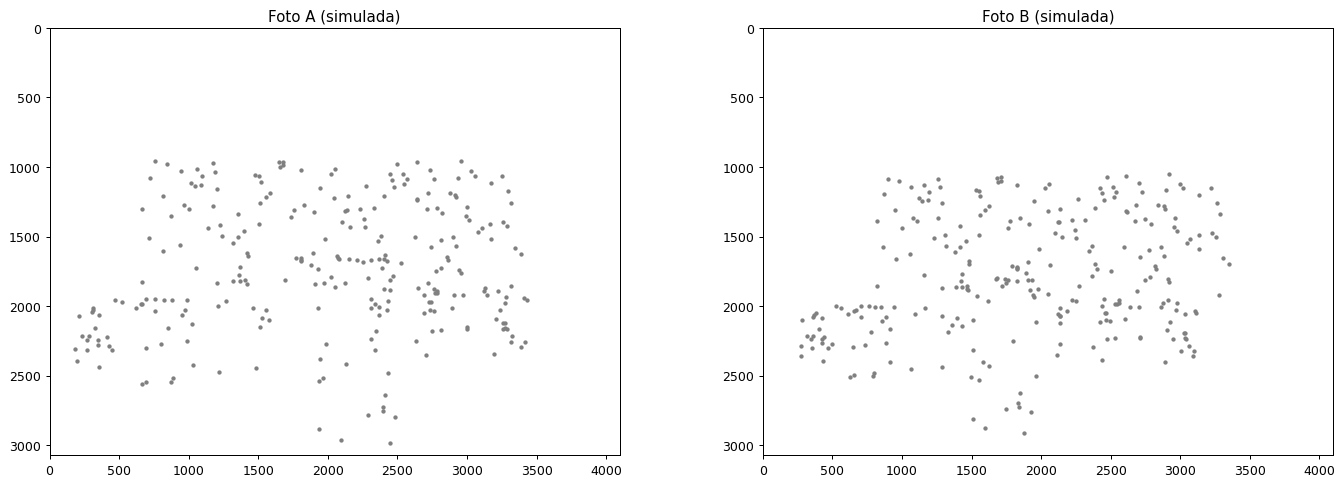

In [4]:
traces = [trace_points(scene_points, 'gray', 2, 'punts de l\'escena')]
traces += traces_camera(camera_A, K_simulation) + traces_camera(camera_B, K_simulation)
traces.append(trace_segment(camera_A['center'], camera_B['center'], 'black', 6, name='base'))
show_3d(traces, "Escena simulada: dues càmeres i una aula")
show_simulated_photos()

### 1.2.- Un píxel és un raig

Si coneixem **K**, cada píxel $\mathbf{x} = (u, v, 1)$ defineix una **direcció** des del centre òptic:

$$\hat{\mathbf{x}} = K^{-1} \mathbf{x} = \begin{bmatrix} (u - c_x)/f_x \\ (v - c_y)/f_y \\ 1 \end{bmatrix}$$

Tots els punts del raig $\mathbf{X}(d) = O_A + d \cdot \hat{\mathbf{x}}$ cauen **al mateix píxel** de la foto A, sigui quina sigui la distància $d$. Per això una foto sola no dona la profunditat.

A la cel·la següent triem un píxel de la foto A i hi col·loquem quatre candidats $X_1, \dots, X_4$ a diferents distàncies. Després mirem on cau cada candidat a la foto B.

In [5]:
pixel_A = np.array([2600.0, 1100.0])          # pixel (u, v) chosen in photo A
candidate_depths = np.array([1.5, 3.0, 5.0, 9.0])  # metres along the optical axis of camera A

candidates_3d = np.vstack([pixel_to_world(pixel_A[None], camera_A, d, K_simulation) for d in candidate_depths])
candidates_in_A = project(candidates_3d, camera_A, K_simulation)
candidates_in_B = project(candidates_3d, camera_B, K_simulation)

print("K^-1 · x_A =", (np.linalg.inv(K_simulation) @ np.append(pixel_A, 1)).round(4), " (direcció del raig)\n")
print(f"{'':4s} {'d (m)':>6s} {'píxel a la foto A':>22s} {'píxel a la foto B':>22s}")
for i, (d, pa, pb) in enumerate(zip(candidate_depths, candidates_in_A, candidates_in_B)):
    print(f"X{i+1:<3d} {d:6.1f} {'(%7.1f, %7.1f)' % tuple(pa):>22s} {'(%7.1f, %7.1f)' % tuple(pb):>22s}")

traces = [trace_points(scene_points, 'lightgray', 2)]
traces += traces_camera(camera_A, K_simulation) + traces_camera(camera_B, K_simulation)
traces.append(trace_segment(camera_A['center'], pixel_to_world(pixel_A[None], camera_A, 10, K_simulation)[0],
                            'green', 6, name='raig del píxel x_A'))
traces.append(trace_points(candidates_3d, 'green', 6, text=[f'X{i+1}' for i in range(len(candidates_3d))]))
for candidate in candidates_3d:
    traces.append(trace_segment(camera_B['center'], candidate, '#d62728', 2, 'dash'))
show_3d(traces, "El raig del píxel x_A i quatre candidats vistos des de la càmera B")

K^-1 · x_A = [ 0.2106 -0.1437  1.    ]  (direcció del raig)

      d (m)      píxel a la foto A      píxel a la foto B
X1      1.5     ( 2600.0,  1100.0)     ( 1434.0,  1541.2)
X2      3.0     ( 2600.0,  1100.0)     ( 2028.5,  1358.8)
X3      5.0     ( 2600.0,  1100.0)     ( 2336.2,  1264.4)
X4      9.0     ( 2600.0,  1100.0)     ( 2571.8,  1192.1)


**Resultat:** a la foto A, els quatre candidats cauen exactament al mateix píxel. A la foto B cauen en píxels diferents, però **alineats**: sobre una recta. Aquesta recta és la **recta epipolar** de $\mathbf{x}_A$. L'homòleg de $\mathbf{x}_A$, sigui quina sigui la seva distància real, ha de ser sobre aquesta recta.

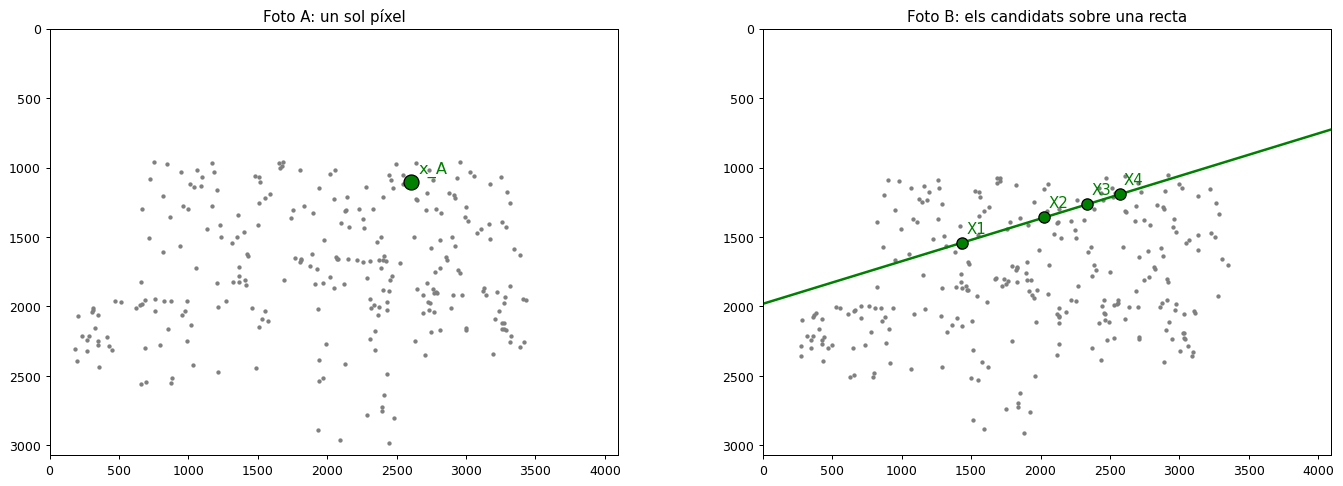

In [6]:
def line_through(p, q):
    """Line (a, b, c) through two pixels: cross product of their homogeneous coordinates."""
    return np.cross(np.append(p, 1), np.append(q, 1))


epipolar_line_B = line_through(candidates_in_B[0], candidates_in_B[-1])
ends = line_endpoints(epipolar_line_B, SIM_WIDTH, SIM_HEIGHT)

def draw_A(ax):
    ax.plot(*pixel_A, 'o', color='green', ms=12, mec='black')
    ax.annotate('x_A', pixel_A + [60, -60], color='green', fontsize=13)

def draw_B(ax):
    ax.plot(ends[:, 0], ends[:, 1], '-', color='green', lw=2)
    for i, p in enumerate(candidates_in_B):
        ax.plot(*p, 'o', color='green', ms=9, mec='black')
        ax.annotate(f'X{i+1}', p + [30, -70], color='green', fontsize=12)

show_simulated_photos(draw_A, draw_B, "Foto A: un sol píxel", "Foto B: els candidats sobre una recta")

### 1.3.- Interactiu: movem el punt al llarg del raig

Mou el control `distància` per desplaçar el punt 3D al llarg del raig de $\mathbf{x}_A$. A la foto A el punt no es mou. A la foto B, el punt **recorre la recta epipolar** i mai no en surt.

> Si el control no apareix (per exemple, en una còpia ja executada), torna a executar la cel·la.

In [7]:
def show_point_on_ray(distance=4.0):
    point_3d = pixel_to_world(pixel_A[None], camera_A, distance, K_simulation)
    point_B = project(point_3d, camera_B, K_simulation)[0]

    def draw_A(ax):
        ax.plot(*pixel_A, 'o', color='green', ms=12, mec='black')

    def draw_B(ax):
        ax.plot(ends[:, 0], ends[:, 1], '-', color='green', lw=1.5, alpha=0.6)
        ax.plot(*point_B, 'o', color='orange', ms=14, mec='black')

    show_simulated_photos(draw_A, draw_B, "Foto A: el punt no es mou",
                          f"Foto B: punt a {distance:.1f} m -> (u, v) = ({point_B[0]:.0f}, {point_B[1]:.0f})")


interact(show_point_on_ray, distance=FloatSlider(value=4.0, min=1.2, max=12.0, step=0.2, description='distància (m)'));

interactive(children=(FloatSlider(value=4.0, description='distància (m)', max=12.0, min=1.2, step=0.2), Output…

### 1.4.- El pla epipolar

Per què és una recta? Perquè el raig de $\mathbf{x}_A$ i el centre òptic $O_B$ defineixen un **pla**: el **pla epipolar**. Conté:

* els dos centres òptics $O_A$ i $O_B$ (i, per tant, la **base**),
* el punt real $\mathbf{X}$,
* els dos píxels $\mathbf{x}_A$ i $\mathbf{x}_B$.

Un pla talla cada foto en una recta: les **rectes epipolars** $\mathbf{l}_A$ i $\mathbf{l}_B$. La base travessa cada pla imatge en un punt: els **epipols** $\mathbf{e}_A$ i $\mathbf{e}_B$. L'epipol $\mathbf{e}_B$ és on es veuria el centre òptic $O_A$ des de la càmera B, i al revés.

A la figura, l'epipol queda fora del fotograma (és el cas habitual): les rectes epipolars es dibuixen allargades fins a l'epipol.

In [8]:
epipole_A = project(camera_B['center'][None], camera_A, K_simulation)[0]   # where O_B is seen from A
epipole_B = project(camera_A['center'][None], camera_B, K_simulation)[0]   # where O_A is seen from B
print(f"Epipol a la foto A: ({epipole_A[0]:.0f}, {epipole_A[1]:.0f}) px")
print(f"Epipol a la foto B: ({epipole_B[0]:.0f}, {epipole_B[1]:.0f}) px   (la foto fa {SIM_WIDTH} x {SIM_HEIGHT})")


epipole_A_3d = pixel_on_image_plane(epipole_A, camera_A, K_simulation)[0]
epipole_B_3d = pixel_on_image_plane(epipole_B, camera_B, K_simulation)[0]


def base_extremes():
    """The base line extended until it crosses both image planes (at the epipoles)."""
    base = camera_B['center'] - camera_A['center']
    candidates = [camera_A['center'], camera_B['center'], epipole_A_3d, epipole_B_3d]
    params = [np.dot(p - camera_A['center'], base) / np.dot(base, base) for p in candidates]
    return camera_A['center'] + min(params) * base, camera_A['center'] + max(params) * base


def epipolar_plane_traces(point_3d, color, opacity=0.25, label=None, show_rays=True):
    """Epipolar plane of a 3D point and its intersection with both image planes (epipolar lines)."""
    start, end = base_extremes()
    traces = [trace_triangle(start, end, point_3d, color, opacity, label), trace_points(point_3d[None], color, 5)]
    if show_rays:
        traces += [trace_segment(camera_A['center'], point_3d, color, 3), trace_segment(camera_B['center'], point_3d, color, 3)]
    for camera, epipole in ((camera_A, epipole_A), (camera_B, epipole_B)):
        pixel = project(point_3d[None], camera, K_simulation)[0]
        line = line_through(epipole, pixel)
        inside = line_endpoints(line, SIM_WIDTH, SIM_HEIGHT)
        if inside is None:
            continue
        inside_3d = pixel_on_image_plane(inside, camera, K_simulation)
        traces.append(trace_segment(inside_3d[0], inside_3d[1], color, 6))                     # epipolar line (inside the photo)
        nearest = inside_3d[np.argmin(np.linalg.norm(inside - epipole, axis=1))]
        traces.append(trace_segment(pixel_on_image_plane(epipole, camera, K_simulation)[0], nearest, color, 2, 'dot'))
    return traces


def base_traces():
    start, end = base_extremes()
    return [trace_segment(start, end, 'black', 2, 'dash'),
            trace_segment(camera_A['center'], camera_B['center'], 'black', 7, name='base'),
            trace_points(np.vstack([epipole_A_3d, epipole_B_3d]), 'black', 5, text=['e_A', 'e_B'])]


point_X = candidates_3d[2]
traces = [trace_points(scene_points, 'lightgray', 2)]
traces += traces_camera(camera_A, K_simulation) + traces_camera(camera_B, K_simulation) + base_traces()
traces += epipolar_plane_traces(point_X, 'darkorange', 0.35, 'pla epipolar de X')
show_3d(traces, "El pla epipolar: O_A, O_B, X i els dos píxels són al mateix pla")

Epipol a la foto A: (-2563, 2648) px
Epipol a la foto B: (-1634, 2482) px   (la foto fa 4096 x 3072)


#### Un pla per a cada punt

Cada punt de l'escena té **el seu propi pla epipolar**. Tots contenen la base i, per tant, **giren al voltant de la base** com les pàgines d'un llibre obert al voltant del llom. Per això totes les rectes epipolars d'una foto passen per l'epipol.

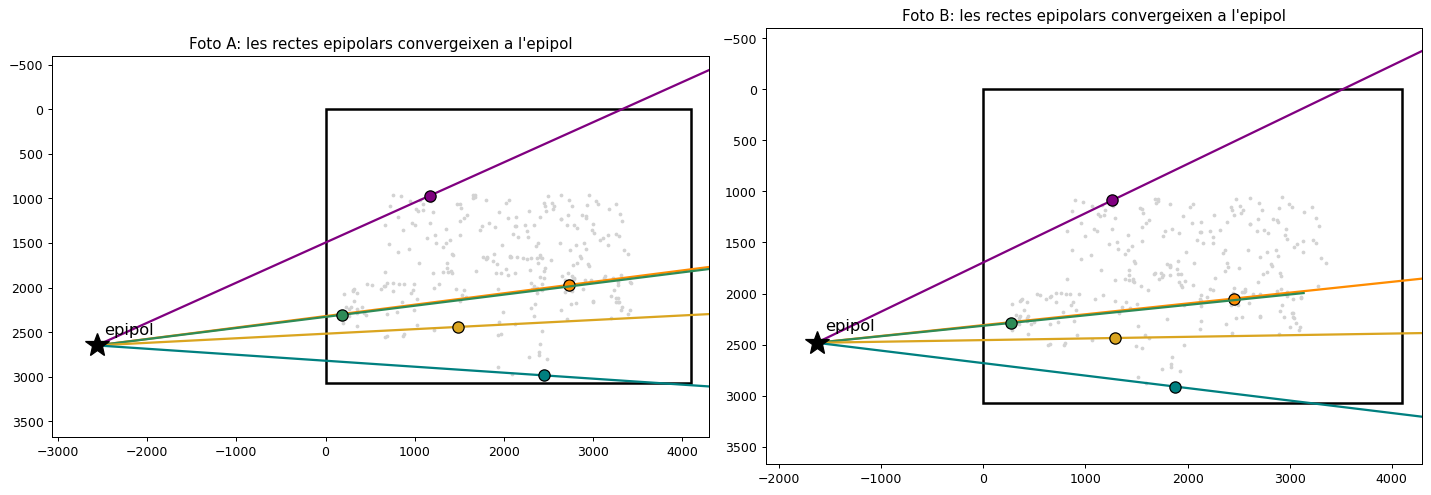

In [9]:
book_points = scene_points[pick_spread_points(pixels_A, 5)]
plane_colors = ['darkorange', 'seagreen', 'purple', 'goldenrod', 'teal']

traces = traces_camera(camera_A, K_simulation) + traces_camera(camera_B, K_simulation) + base_traces()
for point, color in zip(book_points, plane_colors):
    traces += epipolar_plane_traces(point, color, 0.22, show_rays=False)
show_3d(traces, "Cinc punts, cinc plans epipolars: tots giren al voltant de la base (gira la figura!)", eye=(1.9, -0.9, 0.45))


def draw_lines_to_epipole(ax, points_2d, epipole, colors):
    for p, color in zip(points_2d, colors):
        far = p + 1.5 * (p - epipole)
        ax.plot([epipole[0], far[0]], [epipole[1], far[1]], '-', color=color, lw=1.8)
        ax.plot(*p, 'o', color=color, ms=9, mec='black')
    ax.plot(*epipole, '*', color='black', ms=20)
    ax.annotate('epipol', epipole + [80, -120], fontsize=13)
    ax.add_patch(plt.Rectangle((0, 0), SIM_WIDTH, SIM_HEIGHT, fill=False, ec='black', lw=2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, camera, epipole, name in ((axes[0], camera_A, epipole_A, 'A'), (axes[1], camera_B, epipole_B, 'B')):
    pts = project(book_points, camera, K_simulation)
    ax.scatter(*project(scene_points, camera, K_simulation).T, s=4, c='lightgray')
    draw_lines_to_epipole(ax, pts, epipole, plane_colors)
    ax.set_xlim(min(-200, epipole[0] - 500), SIM_WIDTH + 200); ax.set_ylim(SIM_HEIGHT + 600, -600)
    ax.set_aspect('equal'); ax.set_title(f"Foto {name}: les rectes epipolars convergeixen a l'epipol")
plt.tight_layout(); plt.show()

### 1.5.- La condició de coplanarietat

Si $\mathbf{x}_A$ i $\mathbf{x}_B$ són homòlegs de debò, els dos raigs **es tallen** al punt $\mathbf{X}$. Dues rectes que es tallen i la base són al mateix pla: és la **condició de coplanarietat** de la fotogrametria. Tres vectors són coplanaris quan el seu **producte mixt** és zero:

$$\mathbf{b} \cdot (\mathbf{r}_A \times \mathbf{r}_B) = 0$$

on $\mathbf{b} = O_B - O_A$ és la base i $\mathbf{r}_A$, $\mathbf{r}_B$ són les direccions dels dos raigs, expressades en un mateix sistema de coordenades.

Si la parella és incorrecta, els raigs **es creuen sense tocar-se**. La distància mínima entre els dos raigs és:

$$d_{\text{raigs}} = \frac{|\mathbf{b} \cdot (\mathbf{r}_A \times \mathbf{r}_B)|}{\|\mathbf{r}_A \times \mathbf{r}_B\|}$$

Ho comprovem amb tres casos:

1. una parella **correcta**;
2. una parella **incorrecta fora de la recta epipolar**;
3. una parella **incorrecta però sobre la recta epipolar**: un píxel de B que és sobre la recta de $\mathbf{x}_A$, però que no és el seu homòleg. A la cel·la següent fem servir $\mathbf{r} = R^T K^{-1}\mathbf{x}$: és la direcció del raig $K^{-1}\mathbf{x}$ girada al sistema comú de l'escena. Com es construeix $R$ ho veurem a S6.

In [10]:
def ray_direction(pixel, camera, camera_matrix):
    direction = camera['R'].T @ np.linalg.inv(camera_matrix) @ np.append(pixel, 1)
    return direction / np.linalg.norm(direction)


def coplanarity(pixel_A_, pixel_B_, cam_A, cam_B, camera_matrix):
    base = cam_B['center'] - cam_A['center']
    r_A = ray_direction(pixel_A_, cam_A, camera_matrix)
    r_B = ray_direction(pixel_B_, cam_B, camera_matrix)
    cross = np.cross(r_A, r_B)
    triple_product = base @ cross
    return triple_product, abs(triple_product) / np.linalg.norm(cross)


index_X, index_wrong = 160, 143
correct = coplanarity(pixels_A[index_X], pixels_B[index_X], camera_A, camera_B, K_simulation)
wrong = coplanarity(pixels_A[index_X], pixels_B[index_wrong], camera_A, camera_B, K_simulation)

# Case 3: a pixel of B ON the epipolar line of x_A, 400 px away from the true homologue
line_of_X = line_through(epipole_B, pixels_B[index_X])
direction_on_line = np.array([line_of_X[1], -line_of_X[0]]) / np.hypot(line_of_X[0], line_of_X[1])
pixel_on_line = pixels_B[index_X] + 400 * direction_on_line
on_line = coplanarity(pixels_A[index_X], pixel_on_line, camera_A, camera_B, K_simulation)

print(f"1. Correcta:                  b·(rA x rB) = {correct[0]: .2e}   ·   distància entre raigs = {correct[1] * 100:6.2f} cm")
print(f"2. Incorrecta, fora de recta: b·(rA x rB) = {wrong[0]: .2e}   ·   distància entre raigs = {wrong[1] * 100:6.2f} cm")
print(f"3. Incorrecta, sobre recta:   b·(rA x rB) = {on_line[0]: .2e}   ·   distància entre raigs = {on_line[1] * 100:6.2f} cm")

traces = traces_camera(camera_A, K_simulation) + traces_camera(camera_B, K_simulation)
traces.append(trace_segment(camera_A['center'], camera_B['center'], 'black', 6, name='base'))
ray_A = pixel_to_world(pixels_A[index_X][None], camera_A, 11, K_simulation)[0]
ray_B_ok = pixel_to_world(pixels_B[index_X][None], camera_B, 11, K_simulation)[0]
ray_B_bad = pixel_to_world(pixels_B[index_wrong][None], camera_B, 11, K_simulation)[0]
traces.append(trace_segment(camera_A['center'], ray_A, 'green', 5, name='raig de x_A'))
traces.append(trace_segment(camera_B['center'], ray_B_ok, 'seagreen', 5, 'dash', name='raig de x_B correcte (es tallen)'))
traces.append(trace_segment(camera_B['center'], ray_B_bad, 'red', 5, 'dash', name='raig de x_B incorrecte (es creuen)'))
ray_B_on_line = pixel_to_world(pixel_on_line[None], camera_B, 11, K_simulation)[0]
traces.append(trace_segment(camera_B['center'], ray_B_on_line, 'darkorange', 5, 'dash',
                            name='raig de x_B incorrecte sobre la recta (es tallen en un altre punt)'))
traces.append(trace_points(scene_points[index_X][None], 'black', 6, text=['X']))

# Closest points of the two crossing rays: the gap that the coplanarity condition measures
r_A = ray_direction(pixels_A[index_X], camera_A, K_simulation)
r_B = ray_direction(pixels_B[index_wrong], camera_B, K_simulation)
base = camera_B['center'] - camera_A['center']
solution = np.linalg.lstsq(np.column_stack([r_A, -r_B]), base, rcond=None)[0]
closest_A, closest_B = camera_A['center'] + solution[0] * r_A, camera_B['center'] + solution[1] * r_B
traces.append(trace_segment(closest_A, closest_B, 'black', 8, name=f'separació entre raigs: {wrong[1] * 100:.0f} cm'))
show_3d(traces, "Coplanarietat: raigs que es tallen i raigs que es creuen")

1. Correcta:                  b·(rA x rB) = -4.16e-17   ·   distància entre raigs =   0.00 cm
2. Incorrecta, fora de recta: b·(rA x rB) = -2.57e-02   ·   distància entre raigs =  33.32 cm
3. Incorrecta, sobre recta:   b·(rA x rB) = -8.33e-17   ·   distància entre raigs =   0.00 cm


**Resultat:** el cas 3 també dona producte mixt 0: els raigs es tallen, però en un **altre punt** de l'espai (mira el raig taronja a la figura). La coplanarietat és una condició **necessària però no suficient**:

* dos punts homòlegs **sempre** la compleixen;
* complir-la **no garanteix** que siguin homòlegs: qualsevol punt de la recta epipolar la compleix.

La geometria ens diu **on no pot ser** l'homòleg (fora de la recta), però no **quin punt** de la recta és. Per decidir-ho cal que els punts **s'assemblin** (descriptors de S4, correlació).

#### I si no hi ha base?

Si la càmera B és **al mateix lloc** que la A (només ha girat), la base és $\mathbf{b} = \mathbf{0}$ i el producte mixt val zero **per a qualsevol parella**, correcta o no. La condició no diu res: **sense base no hi ha geometria epipolar**. Per això, en fotogrametria, entre foto i foto cal **desplaçar-se**.

In [11]:
camera_B_rotation_only = make_camera(camera_A['center'], yaw_deg=-15, name='B', color='#d62728')
pixels_B_rot = project(scene_points, camera_B_rotation_only, K_simulation)
for name, j in (("correcta", index_X), ("incorrecta", index_wrong)):
    value, _ = coplanarity(pixels_A[index_X], pixels_B_rot[j], camera_A, camera_B_rotation_only, K_simulation)
    print(f"Sense base, parella {name:10s}: b·(rA x rB) = {value: .2e}")

Sense base, parella correcta  : b·(rA x rB) =  0.00e+00
Sense base, parella incorrecta: b·(rA x rB) =  0.00e+00


# PART 2 — La matriu fonamental F amb fotos reals

Ara passem a fotos reals de l'aula. Aquí ja no coneixem els punts 3D ni on eren les càmeres: **només tenim píxels**. L'objectiu és trobar una matriu que, a partir de parelles d'homòlegs, ens doni la recta epipolar de qualsevol punt.

### 2.1.- Dades

| Fitxer | Contingut |
|---|---|
| `aula_A.jpg`, `aula_B.jpg` | Dues fotos de l'aula fetes des de llocs diferents |
| `camera_calibration.xml` | Calibratge del mateix mòbil (S1): K i distorsió |

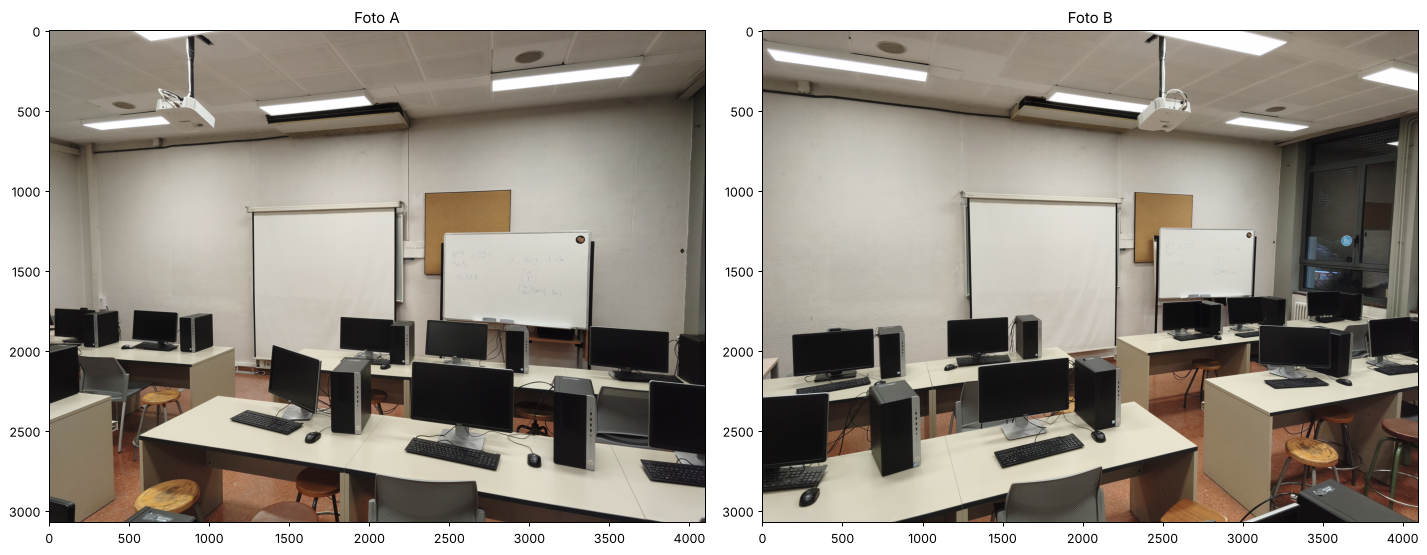

In [ ]:
IMAGE_A_PATH, IMAGE_B_PATH, CALIBRATION_PATH = 'aula_A.jpg', 'aula_B.jpg', 'camera_calibration.xml'

missing_files = [p for p in (IMAGE_A_PATH, IMAGE_B_PATH, CALIBRATION_PATH) if not os.path.exists(p)]
if missing_files and IN_COLAB:
    print("Falten aquests fitxers:", missing_files, "-> puja'ls ara")
    files.upload()

image_A_rgb = cv2.cvtColor(cv2.imread(IMAGE_A_PATH), cv2.COLOR_BGR2RGB)
image_B_rgb = cv2.cvtColor(cv2.imread(IMAGE_B_PATH), cv2.COLOR_BGR2RGB)
image_height, image_width = image_A_rgb.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(image_A_rgb); axes[0].set_title("Foto A")
axes[1].imshow(image_B_rgb); axes[1].set_title("Foto B")
plt.tight_layout(); plt.show()

### 2.2.- La K de S1 i la correcció de la distorsió

Llegim la K i la distorsió del calibratge:

$$K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix} \qquad (k_1, k_2, p_1, p_2, k_3)$$

**Orientació.** El calibratge es va fer amb el mòbil **en vertical** (3072 × 4096) i les fotos de l'aula són **horitzontals** (4096 × 3072). Els eixos de la imatge han girat 90°: les focals s'intercanvien ($f_x \leftrightarrow f_y$), el punt principal passa a $(c_y,\; W_{vertical} - 1 - c_x)$ i els coeficients tangencials també giren. La distorsió radial no canvia.

**Distorsió.** Tota la geometria epipolar suposa el model pinhole: raigs rectes i, per tant, rectes epipolars rectes. La matriu F que calcularem pot "absorbir" la K, perquè K és una transformació **lineal**. La distorsió no és lineal (corba les rectes) i F no la pot absorbir. Per això **corregim la distorsió** abans de res: `cv2.undistort` amb `newCameraMatrix = K` genera imatges sense distorsió amb la mateixa K.

In [ ]:
def load_calibration(path):
    storage = cv2.FileStorage(path, cv2.FILE_STORAGE_READ)
    camera_matrix = storage.getNode('camera_matrix').mat()
    distortion = storage.getNode('dist_coeffs').mat().ravel()
    width, height = int(storage.getNode('image_width').real()), int(storage.getNode('image_height').real())
    storage.release()
    return camera_matrix, distortion, width, height


def rotate_calibration_to_landscape(camera_matrix, distortion, portrait_width):
    """Portrait calibration -> landscape calibration (u_land = v_port, v_land = W_port - 1 - u_port)."""
    fx, fy, cx, cy = camera_matrix[0, 0], camera_matrix[1, 1], camera_matrix[0, 2], camera_matrix[1, 2]
    k1, k2, p1, p2, k3 = distortion
    landscape_matrix = np.array([[fy, 0, cy], [0, fx, (portrait_width - 1) - cx], [0, 0, 1.0]])
    return landscape_matrix, np.array([k1, k2, -p2, p1, k3])


K_calibration, dist_calibration, calibration_width, calibration_height = load_calibration(CALIBRATION_PATH)
if calibration_height > calibration_width and image_width > image_height:
    K, dist_coeffs = rotate_calibration_to_landscape(K_calibration, dist_calibration, calibration_width)
else:
    K, dist_coeffs = K_calibration.copy(), dist_calibration.copy()

print("K (fotos horitzontals):\n", K)
print("Distorsió:", dist_coeffs)

undistorted_A = cv2.undistort(image_A_rgb, K, dist_coeffs, None, K)
undistorted_B = cv2.undistort(image_B_rgb, K, dist_coeffs, None, K)

K (fotos horitzontals):
 [[2750.347     0.     2020.705 ]
 [   0.     2763.4726 1497.0166]
 [   0.        0.        1.    ]]
Distorsió: [ 0.0085  0.1484 -0.0021 -0.0031 -0.1872]


### 2.3.- Parelles d'homòlegs

Busquem homòlegs amb **SIFT**, com a S4. Una part de les parelles seran errònies (objectes repetits: monitors, teclats...). En aquesta part volem entendre **com es calcula F**, i per això fem servir un filtre d'OpenCV que elimina les parelles errònies. **Aquest filtre és RANSAC, i a la Part 4 el programarem nosaltres.**

Parelles SIFT: 338   ·   parelles correctes després del filtre: 111


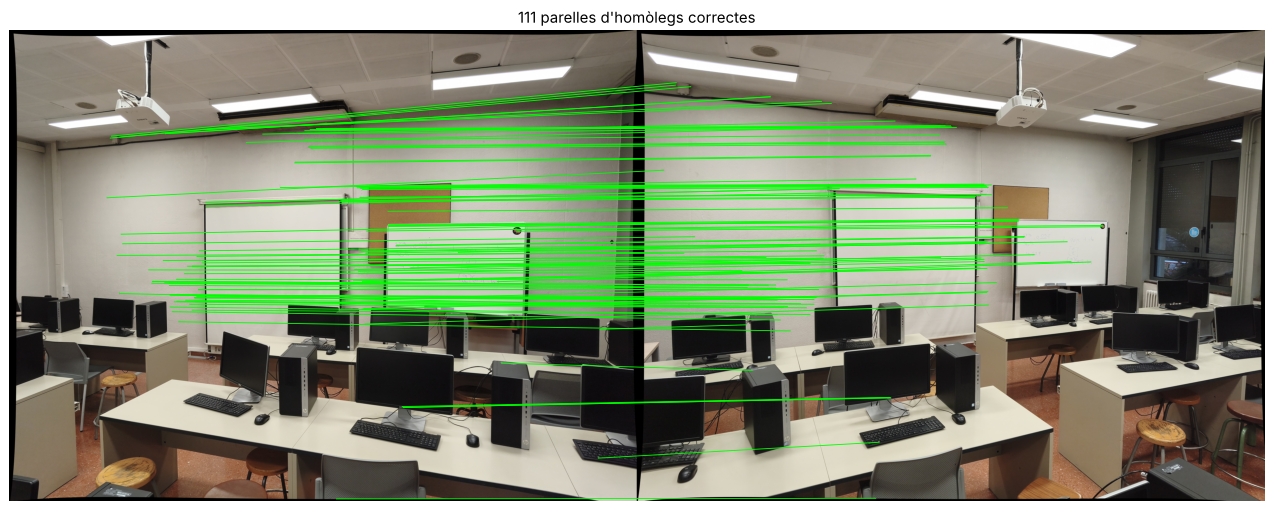

In [ ]:
def detect_and_match(image_1, image_2, scale=0.75, ratio=0.75):
    """SIFT on a downscaled copy + Lowe ratio test + mutual check. Returns full-resolution pixel coordinates."""
    sift = cv2.SIFT_create(contrastThreshold=0.01)
    keypoints, descriptors = [], []
    for image in (image_1, image_2):
        small = cv2.resize(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY), None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        kp, desc = sift.detectAndCompute(small, None)
        keypoints.append(np.array([k.pt for k in kp]) / scale)
        descriptors.append(desc)
    matcher = cv2.BFMatcher(cv2.NORM_L2)
    knn = matcher.knnMatch(descriptors[0], descriptors[1], k=2)
    reverse = {m.queryIdx: m.trainIdx for m in matcher.match(descriptors[1], descriptors[0])}
    good = [m for m, n in knn if m.distance < ratio * n.distance and reverse.get(m.trainIdx) == m.queryIdx]
    points_1 = np.array([keypoints[0][m.queryIdx] for m in good])
    points_2 = np.array([keypoints[1][m.trainIdx] for m in good])
    return points_1, points_2


matches_A, matches_B = detect_and_match(undistorted_A, undistorted_B)

cv2.setRNGSeed(RANDOM_SEED)
_, opencv_mask = cv2.findFundamentalMat(matches_A, matches_B, cv2.USAC_MAGSAC, 1.5, 0.999, 10000)
is_good = opencv_mask.ravel().astype(bool)
good_A, good_B = matches_A[is_good], matches_B[is_good]

print(f"Parelles SIFT: {len(matches_A)}   ·   parelles correctes després del filtre: {len(good_A)}")

canvas = np.hstack([undistorted_A, undistorted_B])
plt.figure(figsize=(18, 7)); plt.imshow(canvas)
for p, q in zip(good_A, good_B):
    plt.plot([p[0], q[0] + image_width], [p[1], q[1]], '-', color='lime', lw=0.7)
plt.title(f"{len(good_A)} parelles d'homòlegs correctes"); plt.axis('off'); plt.show()

### 2.4.- La restricció epipolar és una equació per a cada parella

La matriu fonamental $F$ és una matriu $3 \times 3$ que, multiplicada per un píxel de la foto A, dona la seva **recta epipolar** a la foto B:

$$\mathbf{l}_B = F \, \mathbf{x}_A = \begin{bmatrix} f_{11} & f_{12} & f_{13} \\ f_{21} & f_{22} & f_{23} \\ f_{31} & f_{32} & f_{33} \end{bmatrix} \begin{bmatrix} u_A \\ v_A \\ 1 \end{bmatrix} = \begin{bmatrix} a \\ b \\ c \end{bmatrix}$$

$(a, b, c)$ són els coeficients de la recta en **forma general** $a\,u + b\,v + c = 0$. Fem servir aquesta forma, i no $v = m\,u + n$, perquè també representa rectes verticals ($b = 0$), i perquè $(a, b, c)$ i $(2a, 2b, 2c)$ són la mateixa recta: igual que $F$, una recta està definida **tret d'escala**.

Si $\mathbf{x}_B$ és sobre aquesta recta, $a\,u_B + b\,v_B + c = 0$. Escrit amb matrius, és la **restricció epipolar**:

$$\mathbf{x}_B^T \, F \, \mathbf{x}_A = \begin{bmatrix} u_B & v_B & 1 \end{bmatrix} \begin{bmatrix} f_{11} & f_{12} & f_{13} \\ f_{21} & f_{22} & f_{23} \\ f_{31} & f_{32} & f_{33} \end{bmatrix} \begin{bmatrix} u_A \\ v_A \\ 1 \end{bmatrix} = 0$$

Si desenvolupem el producte, surt **una equació lineal** en els 9 elements de $F$:

$$u_B u_A \, f_{11} + u_B v_A \, f_{12} + u_B \, f_{13} + v_B u_A \, f_{21} + v_B v_A \, f_{22} + v_B \, f_{23} + u_A \, f_{31} + v_A \, f_{32} + f_{33} = 0$$

Amb $N$ parelles, apilem una fila per parella i obtenim el sistema $A \, \mathbf{f} = \mathbf{0}$:

$$\underbrace{\begin{bmatrix} u_B^1 u_A^1 & u_B^1 v_A^1 & u_B^1 & v_B^1 u_A^1 & v_B^1 v_A^1 & v_B^1 & u_A^1 & v_A^1 & 1 \\ \vdots & & & & & & & & \vdots \\ u_B^N u_A^N & u_B^N v_A^N & u_B^N & v_B^N u_A^N & v_B^N v_A^N & v_B^N & u_A^N & v_A^N & 1 \end{bmatrix}}_{A \; (N \times 9)} \underbrace{\begin{bmatrix} f_{11} \\ f_{12} \\ \vdots \\ f_{33} \end{bmatrix}}_{\mathbf{f}} = \mathbf{0}$$

És **el mateix esquema que la DLT de l'homografia (S2)**. Com que $F$ està definida tret d'escala, té 8 incògnites independents: calen **almenys 8 parelles**. Per veure el sistema, fem servir 12 parelles ben repartides per la imatge.

In [ ]:
N_SYSTEM_PAIRS = 12

system_indices = pick_spread_points(good_A, N_SYSTEM_PAIRS)
system_A, system_B = good_A[system_indices], good_B[system_indices]

SYSTEM_COLUMNS = ['uB·uA', 'uB·vA', 'uB', 'vB·uA', 'vB·vA', 'vB', 'uA', 'vA', '1']


def build_epipolar_system(points_A, points_B):
    """One row per pair: [uB·uA, uB·vA, uB, vB·uA, vB·vA, vB, uA, vA, 1]."""
    uA, vA = points_A[:, 0], points_A[:, 1]
    uB, vB = points_B[:, 0], points_B[:, 1]
    return np.column_stack([uB * uA, uB * vA, uB, vB * uA, vB * vA, vB, uA, vA, np.ones(len(uA))])


A_pixels = build_epipolar_system(system_A, system_B)

print("Parelles (en píxels):")
display(pd.DataFrame(np.column_stack([system_A, system_B]), columns=['uA', 'vA', 'uB', 'vB']).round(1))
print(f"\nMatriu A del sistema ({A_pixels.shape[0]} x {A_pixels.shape[1]}):")
display(pd.DataFrame(A_pixels, columns=SYSTEM_COLUMNS).style.format('{:.2e}'))

Parelles (en píxels):


,uA,vA,uB,vB
0,2474.6,1280.1,2487.2,1244.7
1,3844.3,2791.9,1581.3,2688.3
2,660.0,703.6,251.7,358.3
3,2136.2,3057.7,1559.2,3053.7
4,1106.7,1902.1,1001.7,1961.8
5,1655.4,677.6,1684.7,592.4
6,3212.7,2171.8,753.3,2219.3
7,3312.8,1300.7,3039.6,1273.9
8,2564.9,2455.2,1648.9,2395.6
9,3855.9,1950.9,713.1,1922.0



Matriu A del sistema (12 x 9):


,uB·uA,uB·vA,uB,vB·uA,vB·vA,vB,uA,vA,1
0,6.15e+06,3.18e+06,2.49e+03,3.08e+06,1.59e+06,1.24e+03,2.47e+03,1.28e+03,1.00e+00
1,6.08e+06,4.41e+06,1.58e+03,1.03e+07,7.51e+06,2.69e+03,3.84e+03,2.79e+03,1.00e+00
2,1.66e+05,1.77e+05,2.52e+02,2.36e+05,2.52e+05,3.58e+02,6.60e+02,7.04e+02,1.00e+00
3,3.33e+06,4.77e+06,1.56e+03,6.52e+06,9.34e+06,3.05e+03,2.14e+03,3.06e+03,1.00e+00
4,1.11e+06,1.91e+06,1.00e+03,2.17e+06,3.73e+06,1.96e+03,1.11e+03,1.90e+03,1.00e+00
5,2.79e+06,1.14e+06,1.68e+03,9.81e+05,4.01e+05,5.92e+02,1.66e+03,6.78e+02,1.00e+00
6,2.42e+06,1.64e+06,7.53e+02,7.13e+06,4.82e+06,2.22e+03,3.21e+03,2.17e+03,1.00e+00
7,1.01e+07,3.95e+06,3.04e+03,4.22e+06,1.66e+06,1.27e+03,3.31e+03,1.30e+03,1.00e+00
8,4.23e+06,4.05e+06,1.65e+03,6.14e+06,5.88e+06,2.40e+03,2.56e+03,2.46e+03,1.00e+00
9,2.75e+06,1.39e+06,7.13e+02,7.41e+06,3.75e+06,1.92e+03,3.86e+03,1.95e+03,1.00e+00


#### Normalització (Hartley)

Fixa't en les columnes de $A$: unes valen ~$10^7$ (píxel × píxel) i l'última val 1. Un sistema amb columnes tan desequilibrades és **numèricament inestable**: petits errors en els píxels canvien molt la solució.

La solució és **normalitzar** els punts de cada foto abans de muntar el sistema: els portem al voltant de l'origen i els escalem perquè la distància mitjana a l'origen sigui $\sqrt{2}$:

$$\tilde{\mathbf{x}} = T \, \mathbf{x}, \qquad T = \begin{bmatrix} s & 0 & -s\,\bar{u} \\ 0 & s & -s\,\bar{v} \\ 0 & 0 & 1 \end{bmatrix}, \qquad s = \frac{\sqrt{2}}{\text{distància mitjana al centroide}}$$

on $(\bar{u}, \bar{v})$ és el centroide dels punts. Calculem $\tilde{F}$ amb els punts normalitzats i al final tornem a píxels amb $F = T_B^T \, \tilde{F} \, T_A$.

In [ ]:
def normalization_matrix(points):
    centroid = points.mean(axis=0)
    scale = np.sqrt(2) / np.linalg.norm(points - centroid, axis=1).mean()
    return np.array([[scale, 0, -scale * centroid[0]],
                     [0, scale, -scale * centroid[1]],
                     [0, 0, 1]])


def apply_transform(T, points):
    transformed = (T @ to_homogeneous(points).T).T
    return transformed[:, :2] / transformed[:, 2:3]


T_A, T_B = normalization_matrix(system_A), normalization_matrix(system_B)
A_normalized = build_epipolar_system(apply_transform(T_A, system_A), apply_transform(T_B, system_B))

print("T_A =\n", T_A)
print("\nMatriu A amb punts normalitzats:")
display(pd.DataFrame(A_normalized, columns=SYSTEM_COLUMNS).round(3))

T_A =
 [[ 0.0012  0.     -2.6597]
 [ 0.      0.0012 -2.0503]
 [ 0.      0.      1.    ]]

Matriu A amb punts normalitzats:


,uB·uA,uB·vA,uB,vB·uA,vB·vA,vB,uA,vA,1
0,0.310,-0.802,1.427,-0.134,0.346,-0.615,0.217,-0.562,1.0
1,0.387,0.256,0.214,2.384,1.575,1.318,1.809,1.195,1.0
2,2.965,1.930,-1.567,3.411,2.221,-1.802,-1.892,-1.232,1.0
3,-0.032,0.277,0.184,-0.319,2.718,1.807,-0.176,1.504,1.0
4,0.772,-0.091,-0.562,-0.473,0.055,0.345,-1.373,0.161,1.0
5,-0.259,-0.445,0.352,1.095,1.880,-1.489,-0.735,-1.263,1.0
6,-0.962,-0.425,-0.895,0.741,0.327,0.690,1.075,0.475,1.0
7,2.581,-1.166,2.166,-0.687,0.310,-0.576,1.191,-0.538,1.0
8,0.098,0.245,0.304,0.298,0.744,0.926,0.322,0.804,1.0
9,-1.729,-0.207,-0.949,0.531,0.063,0.291,1.823,0.218,1.0


### 2.5.- Solució del sistema amb SVD

Com a S2, el sistema $A\,\mathbf{f} = \mathbf{0}$ es resol amb la **descomposició en valors singulars**:

$$A = U \, \Sigma \, V^T$$

La solució (amb $\|\mathbf{f}\| = 1$) és la **darrera columna de $V$**: la que correspon al valor singular més petit. Amb dades perfectes aquest valor singular seria exactament 0; amb dades reals és molt petit però no zero.

**Forçar rang 2.** Totes les rectes epipolars han de passar per l'epipol. Matemàticament això vol dir que $F$ té **rang 2** ($\det F = 0$): un dels seus valors singulars ha de ser zero. La solució del sistema no ho compleix exactament per culpa del soroll, i ho arreglem així:

$$\tilde{F} = U_F \begin{bmatrix} \sigma_1 & 0 & 0 \\ 0 & \sigma_2 & 0 \\ 0 & 0 & \sigma_3 \end{bmatrix} V_F^T \quad \longrightarrow \quad \tilde{F}' = U_F \begin{bmatrix} \sigma_1 & 0 & 0 \\ 0 & \sigma_2 & 0 \\ 0 & 0 & 0 \end{bmatrix} V_F^T$$

Finalment, desnormalitzem: $F = T_B^T \, \tilde{F}' \, T_A$.

In [ ]:
# Step 1: SVD of the normalized system
U, singular_values_A, Vt = np.linalg.svd(A_normalized)
print("Valors singulars de A:", singular_values_A.round(5))
print("-> el darrer és el més petit: la seva columna de V és la solució\n")

f = Vt[-1]
F_normalized = f.reshape(3, 3)
print("F normalitzada (abans de forçar rang 2):\n", F_normalized.round(4))

# Step 2: force rank 2
U_F, singular_values_F, Vt_F = np.linalg.svd(F_normalized)
print("\nValors singulars de F normalitzada:", singular_values_F.round(5))
singular_values_F[2] = 0
F_normalized_rank2 = U_F @ np.diag(singular_values_F) @ Vt_F
print("Després de forçar rang 2:            ", singular_values_F.round(5))

# Step 3: back to pixels
F = T_B.T @ F_normalized_rank2 @ T_A
F = F / np.linalg.norm(F)
print("\nF en píxels (normalitzada a ||F|| = 1):\n", format_matrix(F))

Valors singulars de A: [7.7306 5.6015 4.6533 3.5727 2.9794 2.2473 1.2174 0.6999 0.002 ]
-> el darrer és el més petit: la seva columna de V és la solució

F normalitzada (abans de forçar rang 2):
 [[ 0.0038 -0.1337 -0.0389]
 [-0.0069 -0.0067 -0.6181]
 [-0.0284  0.773   0.0096]]

Valors singulars de F normalitzada: [0.7858 0.6184 0.0007]
Després de forçar rang 2:             [0.7858 0.6184 0.    ]

F en píxels (normalitzada a ||F|| = 1):
 [[ 1.179e-08 -3.538e-07  5.083e-04]
 [-1.834e-08 -1.774e-08 -1.334e-03]
 [-4.139e-05  2.061e-03 -1.000e+00]]


Els elements de $F$ en píxels són molt petits perquè multipliquen coordenades de píxel entre elles: perquè $u_B u_A f_{11}$ sumi un valor de l'ordre de 1, $f_{11}$ ha de ser de l'ordre de $10^{-7}$. Per separat, els elements no tenen cap significat físic; el que té significat és la matriu sencera.

Agrupem els tres passos en una funció, que farem servir a la resta del notebook:

In [ ]:
def fundamental_8point(points_A, points_B):
    """Normalized 8-point algorithm: normalize, solve A·f = 0 with SVD, force rank 2, denormalize."""
    T_1, T_2 = normalization_matrix(points_A), normalization_matrix(points_B)
    A_system = build_epipolar_system(apply_transform(T_1, points_A), apply_transform(T_2, points_B))
    F_norm = np.linalg.svd(A_system)[2][-1].reshape(3, 3)
    U_, S_, Vt_ = np.linalg.svd(F_norm)
    S_[2] = 0
    F_pixels = T_2.T @ (U_ @ np.diag(S_) @ Vt_) @ T_1
    return F_pixels / np.linalg.norm(F_pixels)


F_function = fundamental_8point(system_A, system_B)
print("Diferència amb el càlcul pas a pas:", np.abs(F_function - F).max())

Diferència amb el càlcul pas a pas: 0.0


### 2.6.- Comprovació: un punt que no hem fet servir

Agafem un punt de la foto A que **no** era entre les 12 parelles del sistema, calculem la seva recta epipolar a la foto B i comprovem si el seu homòleg hi és a sobre.

Amb dades reals, $\mathbf{x}_B^T F \mathbf{x}_A$ mai no dona exactament 0 (els píxels tenen soroll), i el seu valor no té unitats útils perquè depèn de l'escala de $F$. Per això mesurem la **distància en píxels** del punt a la recta, amb la fórmula de sempre per a una recta en forma general:

$$d = \frac{|a\,u_B + b\,v_B + c|}{\sqrt{a^2 + b^2}}$$

Per defecte, la cel·la tria una parella fiable que no era al sistema. Per provar un altre punt, escriu les seves coordenades a `TEST_PIXEL_A` (per exemple `TEST_PIXEL_A = (2500, 2300)`): es dibuixarà la seva recta a la foto B i podràs comprovar a ull que l'homòleg hi és a sobre.

Punt de prova a A: (2327, 1455)
Recta a B: 2.109e-05·u + -1.402e-03·v + 1.902e+00 = 0


Distància de l'homòleg a la recta: 0.50 px


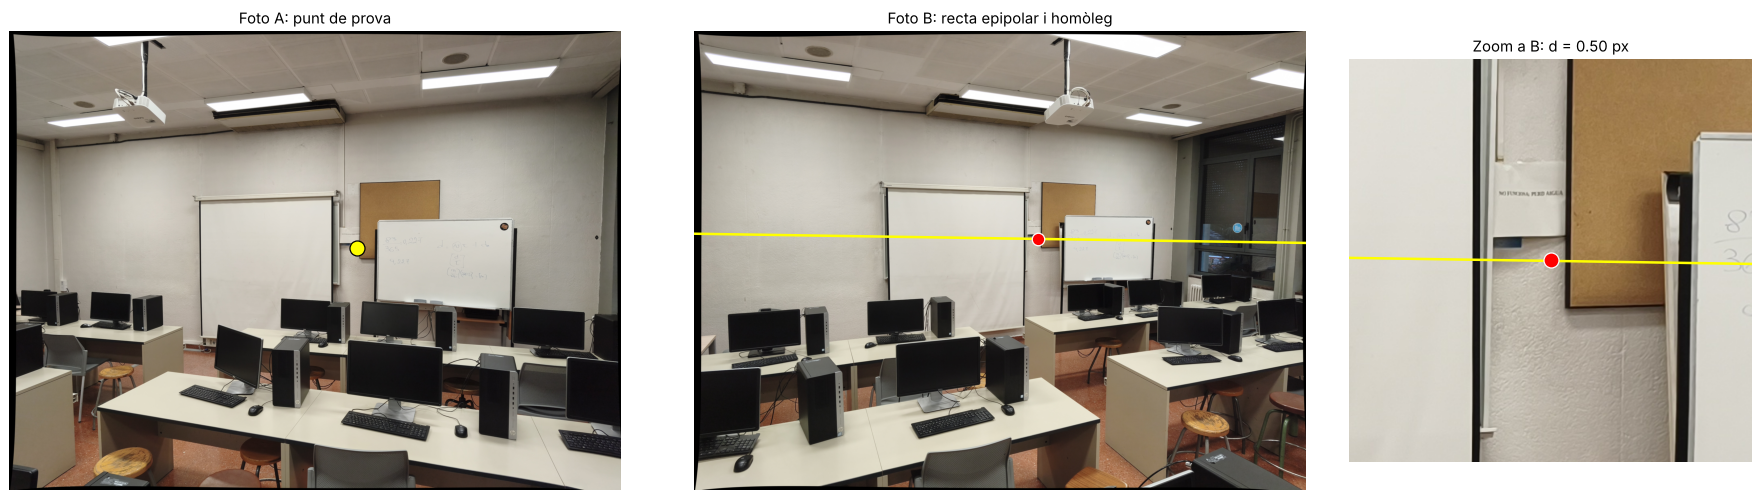

In [ ]:
def epipolar_lines_in_B(F_matrix, points_A):
    """l_B = F · x_A"""
    return (F_matrix @ to_homogeneous(points_A).T).T


def epipolar_lines_in_A(F_matrix, points_B):
    """l_A = F^T · x_B"""
    return (F_matrix.T @ to_homogeneous(points_B).T).T


def point_line_distance(points, lines):
    a, b, c = lines[:, 0], lines[:, 1], lines[:, 2]
    return np.abs(a * points[:, 0] + b * points[:, 1] + c) / np.sqrt(a ** 2 + b ** 2)


TEST_PIXEL_A = None        # <-- write (u, v) of a pixel of photo A to test your own point


def patch_similarity(image_1, image_2, point_1, point_2, half_size=20):
    # Normalized cross-correlation of the patches around both points (1 = identical)
    patches = []
    for image, (u, v) in ((image_1, point_1), (image_2, point_2)):
        u, v = int(round(u)), int(round(v))
        if not (half_size <= u < image.shape[1] - half_size and half_size <= v < image.shape[0] - half_size):
            return -1.0
        patch = cv2.cvtColor(image[v - half_size:v + half_size + 1, u - half_size:u + half_size + 1], cv2.COLOR_RGB2GRAY).astype(float)
        if patch.std() < 25:          # flat patch (plain wall): not a convincing test point
            return -1.0
        patches.append(patch - patch.mean())
    return float((patches[0] * patches[1]).sum() / (np.sqrt((patches[0] ** 2).sum() * (patches[1] ** 2).sum()) + 1e-9))


if TEST_PIXEL_A is None:
    # Default: among the pairs NOT used in the system, the one whose two patches look most alike
    not_used = np.setdiff1d(np.arange(len(good_A)), system_indices)
    similarity = [patch_similarity(undistorted_A, undistorted_B, good_A[i], good_B[i]) for i in not_used]
    test_index = not_used[int(np.argmax(similarity))]
    test_A, test_B = good_A[test_index], good_B[test_index]
else:
    test_A, test_B = np.array(TEST_PIXEL_A, dtype=float), None

test_line = epipolar_lines_in_B(F, test_A[None])[0]
ends = line_endpoints(test_line, image_width, image_height)
print(f"Punt de prova a A: ({test_A[0]:.0f}, {test_A[1]:.0f})")
print(f"Recta a B: {test_line[0]:.3e}·u + {test_line[1]:.3e}·v + {test_line[2]:.3e} = 0")

zoom = 250
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={'width_ratios': [1, 1, 0.6]})
axes[0].imshow(undistorted_A); axes[0].plot(*test_A, 'o', color='yellow', ms=12, mec='black'); axes[0].set_title("Foto A: punt de prova")
axes[1].imshow(undistorted_B); axes[1].plot(ends[:, 0], ends[:, 1], '-', color='yellow', lw=2)
if test_B is not None:
    test_distance = point_line_distance(test_B[None], test_line[None])[0]
    print(f"Distància de l'homòleg a la recta: {test_distance:.2f} px")
    axes[1].plot(*test_B, 'o', color='red', ms=10, mec='white'); axes[1].set_title("Foto B: recta epipolar i homòleg")
    axes[2].imshow(undistorted_B); axes[2].plot(ends[:, 0], ends[:, 1], '-', color='yellow', lw=2)
    axes[2].plot(*test_B, 'o', color='red', ms=12, mec='white')
    axes[2].set_xlim(test_B[0] - zoom, test_B[0] + zoom); axes[2].set_ylim(test_B[1] + zoom, test_B[1] - zoom)
    axes[2].set_title(f"Zoom a B: d = {test_distance:.2f} px")
else:
    axes[1].set_title("Foto B: busca l'homòleg a ull sobre la recta")
    axes[2].imshow(undistorted_A); axes[2].plot(*test_A, '+', color='red', ms=25, mew=2)
    axes[2].set_xlim(test_A[0] - zoom, test_A[0] + zoom); axes[2].set_ylim(test_A[1] + zoom, test_A[1] - zoom)
    axes[2].set_title("Zoom a A: què has de buscar")
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

> ⚠️ **Límit de la geometria epipolar.** La restricció només controla una cosa: la distància del punt a la recta. Una parella errònia que caigui **per casualitat sobre la recta** (sovint un objecte repetit: un altre ordinador, una altra cadira...) passa el filtre i no es pot detectar. Per això, a més de la geometria, els homòlegs també s'han de **semblar** (descriptors, correlació).

#### Les rectes de tots els punts

Dibuixem la recta epipolar de cada una de les 12 parelles, amb el mateix color a les dues fotos. A la foto A fem servir $\mathbf{l}_A = F^T \mathbf{x}_B$ i a la foto B, $\mathbf{l}_B = F \, \mathbf{x}_A$.

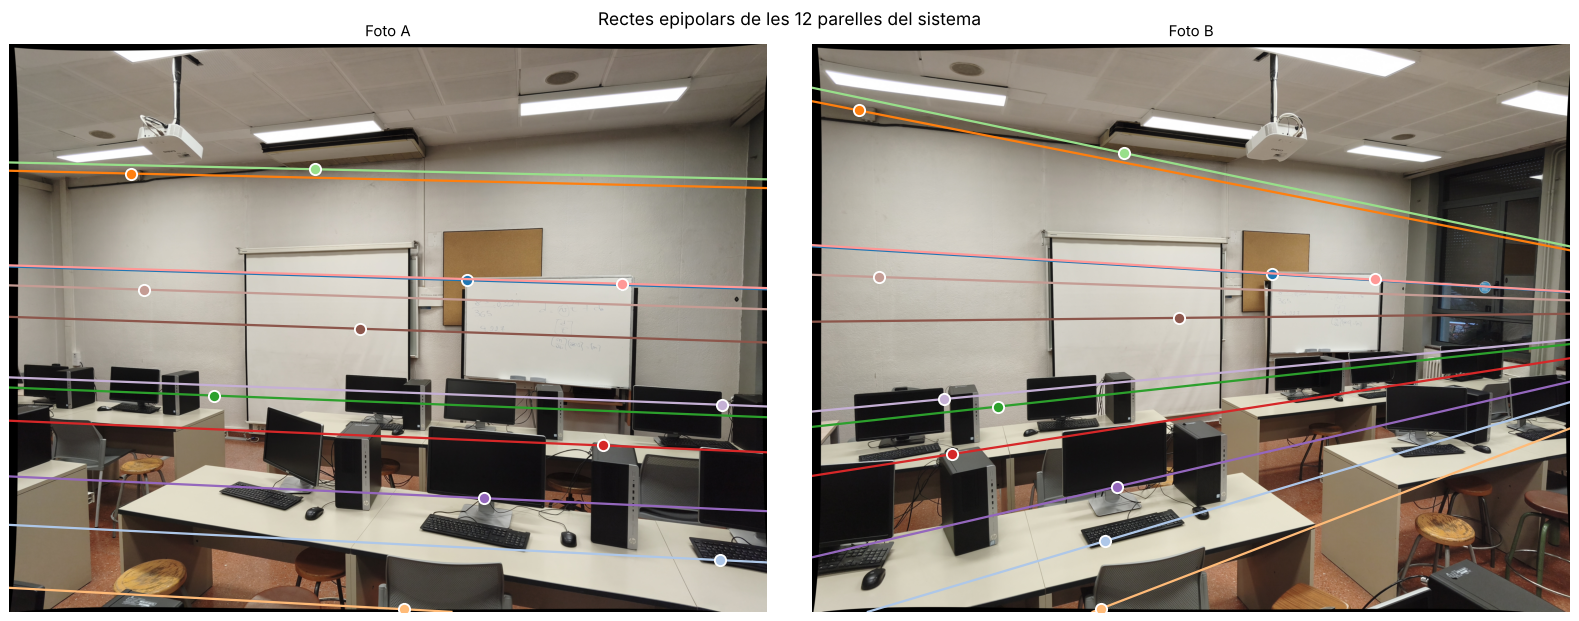

In [ ]:
def draw_epipolar_pairs(F_matrix, image_1, image_2, points_1, points_2, title):
    height, width = image_1.shape[:2]
    colors = plt.cm.tab20(np.arange(len(points_1)) % 20)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for ax, image, points, lines, name in ((axes[0], image_1, points_1, epipolar_lines_in_A(F_matrix, points_2), 'A'),
                                           (axes[1], image_2, points_2, epipolar_lines_in_B(F_matrix, points_1), 'B')):
        ax.imshow(image)
        for point, line, color in zip(points, lines, colors):
            e = line_endpoints(line, width, height)
            if e is not None:
                ax.plot(e[:, 0], e[:, 1], '-', color=color, lw=1.8)
            ax.plot(point[0], point[1], 'o', color=color, ms=9, mec='white', mew=1.5)
        ax.set_xlim(0, width); ax.set_ylim(height, 0); ax.axis('off'); ax.set_title(f"Foto {name}")
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()


draw_epipolar_pairs(F, undistorted_A, undistorted_B, system_A, system_B,
                    "Rectes epipolars de les 12 parelles del sistema")

### 2.7.- L'epipol

Totes les rectes epipolars passen per l'epipol. Això vol dir que l'epipol compleix:

$$F \, \mathbf{e}_A = \mathbf{0}, \qquad F^T \mathbf{e}_B = \mathbf{0}$$

Són dos sistemes del tipus $M\mathbf{x} = \mathbf{0}$, com el de l'apartat 2.5, i es resolen igual, amb la SVD: $\mathbf{e}_A$ és la darrera columna de $V$ i $\mathbf{e}_B$ és la darrera columna de $U$.

**Què representa?** L'epipol de la foto B és **on es veuria el centre òptic de la càmera A** des de la càmera B: la base travessa la foto en aquest punt. Per tant, **F ja sap cap a on és l'altra càmera**, però ho diu en píxels. A la Part 3 ho convertirem en una direcció real (en graus) amb la K.

Epipol a la foto A: (-71799, -957) px
Epipol a la foto B: (5753, 1443) px   (la foto fa 4096 x 3072)


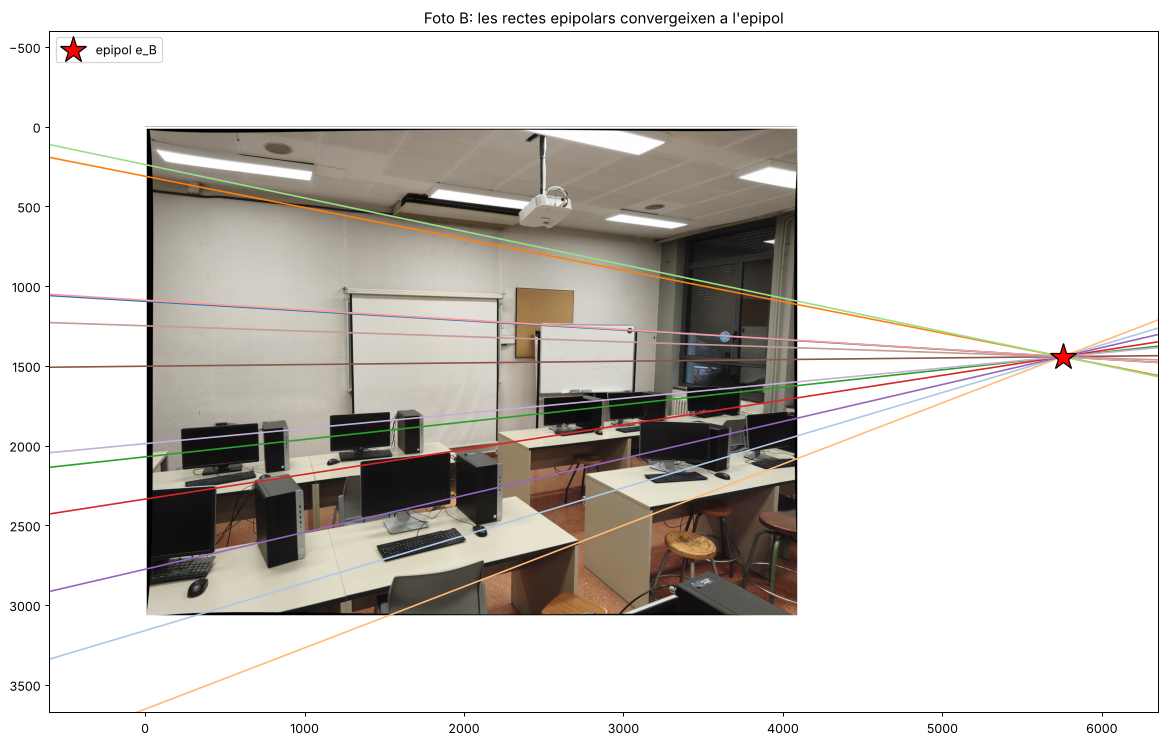

In [ ]:
def epipoles_from_fundamental(F_matrix):
    U_, _, Vt_ = np.linalg.svd(F_matrix)
    e_A, e_B = Vt_[-1], U_[:, -1]
    return e_A / e_A[2], e_B / e_B[2]


epipole_A_real, epipole_B_real = epipoles_from_fundamental(F)
print(f"Epipol a la foto A: ({epipole_A_real[0]:.0f}, {epipole_A_real[1]:.0f}) px")
print(f"Epipol a la foto B: ({epipole_B_real[0]:.0f}, {epipole_B_real[1]:.0f}) px   (la foto fa {image_width} x {image_height})")

if abs(epipole_B_real[0]) < 5 * image_width and abs(epipole_B_real[1]) < 5 * image_height:
    margin = 600
    u_min, u_max = min(0, epipole_B_real[0]) - margin, max(image_width, epipole_B_real[0]) + margin
    v_min, v_max = min(0, epipole_B_real[1]) - margin, max(image_height, epipole_B_real[1]) + margin
    plt.figure(figsize=(16, 16 * (v_max - v_min) / (u_max - u_min)))
    plt.imshow(undistorted_B)
    colors = plt.cm.tab20(np.arange(len(system_A)) % 20)
    for line, color in zip(epipolar_lines_in_B(F, system_A), colors):
        u_values = np.array([u_min, u_max])
        plt.plot(u_values, -(line[0] * u_values + line[2]) / line[1], '-', color=color, lw=1.3)
    plt.plot(*epipole_B_real[:2], '*', color='red', ms=22, mec='black', label="epipol e_B")
    plt.gca().add_patch(plt.Rectangle((0, 0), image_width, image_height, fill=False, ec='white', lw=2))
    plt.xlim(u_min, u_max); plt.ylim(v_max, v_min); plt.legend(loc='upper left')
    plt.title("Foto B: les rectes epipolars convergeixen a l'epipol"); plt.show()
else:
    print("L'epipol és molt lluny: les rectes són pràcticament paral·leles.")

### 2.8.- Comparació amb OpenCV

`cv2.findFundamentalMat` amb l'opció `FM_8POINT` implementa el mateix algorisme. Amb les mateixes 12 parelles ha de donar la mateixa matriu (tret del signe, perquè $F$ i $-F$ són equivalents).

In [ ]:
F_opencv, _ = cv2.findFundamentalMat(system_A, system_B, cv2.FM_8POINT)
F_opencv = F_opencv / np.linalg.norm(F_opencv)
F_opencv = F_opencv * np.sign(F_opencv[2, 2] * F[2, 2])

print("F nostra:\n", format_matrix(F))
print("\nF d'OpenCV:\n", format_matrix(F_opencv))
print("\nDiferència màxima:", np.abs(F - F_opencv).max())

F nostra:
 [[ 1.179e-08 -3.538e-07  5.083e-04]
 [-1.834e-08 -1.774e-08 -1.334e-03]
 [-4.139e-05  2.061e-03 -1.000e+00]]

F d'OpenCV:
 [[ 1.179e-08 -3.538e-07  5.083e-04]
 [-1.834e-08 -1.774e-08 -1.334e-03]
 [-4.139e-05  2.061e-03 -1.000e+00]]

Diferència màxima: 2.492459645793421e-10


# PART 3 — La matriu K, la matriu essencial E i l'orientació relativa

### 3.1.- K: de píxels a direccions

Un píxel, per si sol, no és una direcció: "600 píxels a la dreta del centre" és un angle diferent segons la càmera i el zoom. La **K** és el que converteix píxels en direccions (angles):

$$\hat{\mathbf{x}} = K^{-1}\mathbf{x} \quad\Longrightarrow\quad \tan \alpha_{horitzontal} = \frac{u - c_x}{f_x}, \qquad \tan \alpha_{vertical} = \frac{v - c_y}{f_y}$$

Per exemple, el camp de visió de la càmera surt directament de K:

In [ ]:
def pixel_to_angles(pixel, camera_matrix):
    direction = np.linalg.inv(camera_matrix) @ np.append(pixel, 1)
    return np.degrees(np.arctan(direction[0])), np.degrees(np.arctan(direction[1]))


horizontal_fov = pixel_to_angles([image_width, K[1, 2]], K)[0] - pixel_to_angles([0, K[1, 2]], K)[0]
vertical_fov = pixel_to_angles([K[0, 2], image_height], K)[1] - pixel_to_angles([K[0, 2], 0], K)[1]
print(f"Camp de visió del mòbil: {horizontal_fov:.1f}° en horitzontal x {vertical_fov:.1f}° en vertical")

for example_pixel in ([K[0, 2] + 600, K[1, 2]], [100, 100]):
    h_angle, v_angle = pixel_to_angles(example_pixel, K)
    print(f"Píxel ({example_pixel[0]:.0f}, {example_pixel[1]:.0f}) -> {h_angle:+.1f}° en horitzontal, {v_angle:+.1f}° en vertical")

Camp de visió del mòbil: 73.3° en horitzontal x 58.1° en vertical
Píxel (2621, 1497) -> +12.3° en horitzontal, +0.0° en vertical
Píxel (100, 100) -> -34.9° en horitzontal, -26.8° en vertical


### 3.2.- La matriu essencial E és l'orientació relativa

**F i E fan la mateixa feina**: donar la recta epipolar. La diferència és la "llengua" en què treballen:

* **F** treballa en **píxels**: $\mathbf{x}_B^T \, F \, \mathbf{x}_A = 0$
* **E** treballa en **direccions**: $\hat{\mathbf{x}}_B^T \, E \, \hat{\mathbf{x}}_A = 0$, amb $\hat{\mathbf{x}} = K^{-1}\mathbf{x}$

Si substituïm $\hat{\mathbf{x}} = K^{-1}\mathbf{x}$, surt la relació entre les dues:

$$E = K_B^T \, F \, K_A \qquad \Longleftrightarrow \qquad F = K_B^{-T} \, E \, K_A^{-1}$$

Com que E ja no conté res de com són les càmeres per dins, **només li queda l'orientació relativa**: com està girada la càmera B respecte de la A ($R$) i cap a on s'ha desplaçat ($\mathbf{t}$). És la condició de coplanarietat de l'apartat 1.5, escrita amb una matriu:

$$E = [\mathbf{t}]_\times \, R, \qquad [\mathbf{t}]_\times = \begin{bmatrix} 0 & -t_z & t_y \\ t_z & 0 & -t_x \\ -t_y & t_x & 0 \end{bmatrix}$$

* $R$ (gir de B respecte d'A): **3 paràmetres**.
* $\mathbf{t}$ (direcció de la base): **2 paràmetres**. La seva longitud no es pot saber amb dues fotos: l'escala és desconeguda.
* En total, **5 paràmetres**: exactament els de l'orientació relativa de la fotogrametria clàssica.

A l'escena simulada coneixem $R$ i $\mathbf{t}$, i per tant podem construir la $E$ "de veritat" i comparar-la amb la $E$ que obtenim a partir dels píxels. Com treure $R$ i $\mathbf{t}$ d'una E calculada ho veurem a S6.

In [ ]:
def skew_symmetric(vector):
    x, y, z = vector
    return np.array([[0, -z, y], [z, 0, -x], [-y, x, 0]])


def normalize_matrix(M):
    M = M / np.linalg.norm(M)
    index = np.unravel_index(np.argmax(np.abs(M)), M.shape)
    return M * np.sign(M[index])


# Relative orientation of the simulated camera B with respect to A (A is at the origin, without rotation)
R_relative = camera_B['R']
t_relative = camera_B['t']
E_true = normalize_matrix(skew_symmetric(t_relative) @ R_relative)

# E computed only from pixels: F with the 8-point algorithm, then E = K^T F K
rng = np.random.default_rng(RANDOM_SEED)
noisy_A = pixels_A + rng.normal(0, 0.5, pixels_A.shape)        # 0.5 px of noise, as in real photos
noisy_B = pixels_B + rng.normal(0, 0.5, pixels_B.shape)
F_simulation = fundamental_8point(noisy_A, noisy_B)
E_from_pixels = normalize_matrix(K_simulation.T @ F_simulation @ K_simulation)

print("E construïda amb l'orientació relativa simulada,  E = [t]x R:\n", E_true.round(4))
print("\nE calculada només amb píxels,  E = K^T F K:\n", E_from_pixels.round(4))

E construïda amb l'orientació relativa simulada,  E = [t]x R:
 [[-0.0155 -0.4157  0.1474]
 [ 0.3557  0.      0.5929]
 [-0.1474 -0.5524 -0.0155]]

E calculada només amb píxels,  E = K^T F K:
 [[-0.0154 -0.4161  0.1473]
 [ 0.3563  0.0003  0.5925]
 [-0.1473 -0.5522 -0.0155]]


Les dues matrius coincideixen: **a partir només de píxels i de K, hem recuperat l'orientació relativa** de les dues càmeres, escrita en forma de matriu.

### 3.3.- Experiment: les mateixes càmeres amb zoom

Fem les dues fotos simulades **des dels mateixos llocs**, però amb **zoom 2×** (doble de focal). L'orientació relativa no ha canviat, però la càmera sí.

In [ ]:
K_zoom = K_simulation.copy()
K_zoom[0, 0] *= 2
K_zoom[1, 1] *= 2

pixels_A_zoom = project(scene_points, camera_A, K_zoom)
pixels_B_zoom = project(scene_points, camera_B, K_zoom)
inside = ((pixels_A_zoom[:, 0] > 0) & (pixels_A_zoom[:, 0] < SIM_WIDTH) & (pixels_A_zoom[:, 1] > 0) & (pixels_A_zoom[:, 1] < SIM_HEIGHT) &
          (pixels_B_zoom[:, 0] > 0) & (pixels_B_zoom[:, 0] < SIM_WIDTH) & (pixels_B_zoom[:, 1] > 0) & (pixels_B_zoom[:, 1] < SIM_HEIGHT))

F_zoom = fundamental_8point(pixels_A_zoom[inside], pixels_B_zoom[inside])
E_zoom = normalize_matrix(K_zoom.T @ F_zoom @ K_zoom)
F_no_zoom = fundamental_8point(pixels_A, pixels_B)

print("F amb zoom 1x:\n", format_matrix(normalize_matrix(F_no_zoom)))
print("\nF amb zoom 2x:\n", format_matrix(normalize_matrix(F_zoom)))
print("\nE amb zoom 1x:\n", normalize_matrix(K_simulation.T @ F_no_zoom @ K_simulation).round(4))
print("\nE amb zoom 2x:\n", E_zoom.round(4))

F amb zoom 1x:
 [[ 2.941e-08  7.854e-07 -2.005e-03]
 [-6.720e-07 -5.170e-21 -1.722e-03]
 [ 1.716e-03  1.283e-03  1.000e+00]]

F amb zoom 2x:
 [[ 1.484e-08  3.963e-07 -1.400e-03]
 [-3.391e-07 -2.464e-22 -2.423e-03]
 [ 1.254e-03  2.096e-03  1.000e+00]]

E amb zoom 1x:
 [[-0.0155 -0.4157  0.1474]
 [ 0.3557  0.      0.5929]
 [-0.1474 -0.5524 -0.0155]]

E amb zoom 2x:
 [[-0.0155 -0.4157  0.1474]
 [ 0.3557  0.      0.5929]
 [-0.1474 -0.5524 -0.0155]]


| | Zoom 1× | Zoom 2× |
|---|---|---|
| **F** (píxels) | una matriu | **una altra** |
| **E** (direccions) | $[\mathbf{t}]_\times R$ | **la mateixa** |

* **F** descriu *aquestes dues fotos concretes*: barreja on són les càmeres amb com són (K).
* **E** descriu *només on són les càmeres i cap a on miren*: l'orientació relativa. No depèn de la càmera.

**Quin paper té cada una?** F és el que podem calcular **directament amb els píxels**, sense saber res de la càmera. Si a més coneixem K, li "traiem la càmera" i ens queda E:

$$\text{homòlegs (píxels)} \;\longrightarrow\; F \;\xrightarrow{\;+\,K\;}\; E = K^T F K \;\longrightarrow\; \text{orientació relativa (S6)}$$

F no sobra: amb F sola ja podem comprovar parelles, eliminar errors, buscar homòlegs i rectificar, i és l'única opció quan no coneixem la càmera (fotos d'arxiu o d'internet). Però per passar de les fotos a la **geometria de les càmeres** cal fer el pas a E, i per això cal el calibratge de S1.

### 3.4.- De l'epipol a la direcció de l'altra càmera

A la Part 2 hem vist que l'epipol de la foto B és **on es veu la càmera A**, en píxels. Amb K el podem convertir en una **direcció**, exactament com qualsevol altre píxel (apartat 3.1):

$$\hat{\mathbf{e}}_B = K^{-1}\mathbf{e}_B \qquad \Longrightarrow \qquad \text{angle horitzontal} = \arctan\frac{u_e - c_x}{f_x}, \quad \text{angle vertical} = \arctan\frac{v_e - c_y}{f_y}$$

Aquesta direcció és la **direcció de la base** vista des de la càmera B: **2 dels 5 paràmetres** de l'orientació relativa. Els altres 3 (el gir) també són dins d'E, i els traurem a S6. La **distància** entre les càmeres no apareix enlloc.

Un matís: l'epipol no distingeix si l'altra càmera és en aquesta direcció o just en la contrària (darrere). També ho resoldrem a S6.

Primer ho comprovem a l'escena simulada, on sabem on és de veritat la càmera A:

In [ ]:
def direction_angles(vector):
    # Horizontal and vertical angle (degrees) of a direction in the camera system (Z forward)
    vector = vector if vector[2] >= 0 else -vector        # the epipole does not tell front from back
    return np.degrees(np.arctan2(vector[0], vector[2])), np.degrees(np.arctan2(vector[1], vector[2]))


# Simulation: true direction of camera A seen from camera B, and the one obtained from F + K
true_direction = camera_B['R'] @ (camera_A['center'] - camera_B['center'])
_, epipole_B_sim = epipoles_from_fundamental(F_simulation)
direction_from_F = np.linalg.inv(K_simulation) @ epipole_B_sim

print("SIMULACIÓ: on és la càmera A, vista des de la càmera B")
print("  De veritat:            %+6.1f° en horitzontal, %+6.1f° en vertical" % direction_angles(true_direction))
print("  Amb l'epipol i la K:   %+6.1f° en horitzontal, %+6.1f° en vertical" % direction_angles(direction_from_F))

SIMULACIÓ: on és la càmera A, vista des de la càmera B
  De veritat:             -53.0° en horitzontal,  +19.6° en vertical
  Amb l'epipol i la K:    -53.0° en horitzontal,  +19.6° en vertical


Ara amb les fotos reals. Aquí no coneixem la resposta, però la podem comparar amb el que sabem de com es van fer les fotos. En aquest conveni la $v$ creix cap avall: un angle vertical negatiu vol dir *amunt*.

In [ ]:
F_all_good = fundamental_8point(good_A, good_B)
_, epipole_B_photos = epipoles_from_fundamental(F_all_good)
horizontal, vertical = direction_angles(np.linalg.inv(K) @ epipole_B_photos)

print(f"Epipol a la foto B: ({epipole_B_photos[0]:.0f}, {epipole_B_photos[1]:.0f}) px")
print(f"Des de la càmera B, la càmera A és a {abs(horizontal):.1f}° cap a la {'esquerra' if horizontal < 0 else 'dreta'}"
      f" i {abs(vertical):.1f}° cap {'amunt' if vertical < 0 else 'avall'} de la direcció on mira B")

E_real = normalize_matrix(K.T @ F_all_good @ K)
print("\nE = K^T F K de les fotos de l'aula:\n", E_real.round(4))

Epipol a la foto B: (5778, 1438) px
Des de la càmera B, la càmera A és a 53.8° cap a la dreta i 1.2° cap amunt de la direcció on mira B

E = K^T F K de les fotos de l'aula:
 [[-0.0142  0.4489 -0.0004]
 [ 0.027   0.0215  0.6487]
 [ 0.02   -0.6129  0.0144]]


> OpenCV també pot calcular E directament amb `cv2.findEssentialMat`, que fa servir K i només necessita **5 parelles** per mostra (E té 5 paràmetres). La farem servir a S6 per treure'n el gir i la direcció de la base.

# PART 4 — Parelles errònies i RANSAC

A la Part 2 hem fet servir un filtre d'OpenCV per eliminar les parelles errònies. Ara el programem nosaltres.

### 4.1.- Què passa si hi ha parelles errònies?

Calculem F amb **totes** les parelles de SIFT, sense filtrar, i mirem la distància de cada parella a la seva recta epipolar. Per tenir en compte les dues fotos, fem la mitjana de les distàncies a A i a B:

$$d_{sim} = \tfrac{1}{2}\left( d(\mathbf{x}_B, F\mathbf{x}_A) + d(\mathbf{x}_A, F^T\mathbf{x}_B) \right)$$

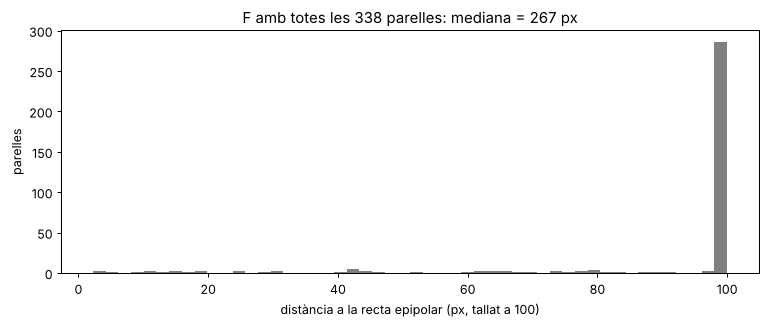

In [ ]:
def symmetric_epipolar_distance(F_matrix, points_A, points_B):
    distance_in_B = point_line_distance(points_B, epipolar_lines_in_B(F_matrix, points_A))
    distance_in_A = point_line_distance(points_A, epipolar_lines_in_A(F_matrix, points_B))
    return 0.5 * (distance_in_A + distance_in_B)


F_all_pairs = fundamental_8point(matches_A, matches_B)
distances_all = symmetric_epipolar_distance(F_all_pairs, matches_A, matches_B)

plt.figure(figsize=(10, 3.5))
plt.hist(np.clip(distances_all, 0, 100), bins=50, color='gray')
plt.xlabel("distància a la recta epipolar (px, tallat a 100)"); plt.ylabel("parelles")
plt.title(f"F amb totes les {len(matches_A)} parelles: mediana = {np.median(distances_all):.0f} px"); plt.show()

Els outliers "estiren" la solució de mínims quadrats i la F resultant no serveix per a ningú. Per calcular F necessitem parelles bones, però per saber quines són bones necessitem F.

### 4.2.- RANSAC

1. Triar **8 parelles a l'atzar** i calcular F amb l'algorisme dels 8 punts.
2. Calcular la distància de **totes** les parelles a la seva recta.
3. Comptar els **inliers**: les parelles per sota d'un llindar (1,5 px).
4. Repetir $N$ vegades i quedar-se la F amb més inliers.
5. Recalcular F amb tots els inliers.

**Quantes vegades cal repetir-ho?** Si una fracció $w$ de les parelles són bones, la probabilitat que una mostra de $s$ parelles sigui tota bona és $w^s$. Per tenir una probabilitat $p = 0{,}99$ que almenys una de les $N$ mostres sigui neta:

$$N = \frac{\log(1 - p)}{\log(1 - w^s)}$$

| Parelles bones ($w$) | $N$ amb mostres de 8 (F) | $N$ amb mostres de 5 (E) |
|---|---|---|
| 90 % | 9 | 6 |
| 70 % | 78 | 26 |
| 50 % | 1.177 | 146 |
| 30 % | 70.188 | 1.893 |

Dues conclusions: com més errors hi ha, moltíssimes més iteracions calen; i com que E necessita mostres més petites (perquè coneixem K), en calen moltes menys.

Amb aquestes fotos, aproximadament un 30 % de les parelles de SIFT són bones. Fem **30.000 intents** (uns segons). La cel·la escriu un missatge cada vegada que troba una F millor que l'anterior, és a dir, que accepta més parelles.

  intent     0: nova millor F, accepta    4 parelles de 338
  intent     2: nova millor F, accepta    7 parelles de 338
  intent    16: nova millor F, accepta   11 parelles de 338
  intent    70: nova millor F, accepta   33 parelles de 338
  intent   312: nova millor F, accepta   36 parelles de 338
  intent   671: nova millor F, accepta   66 parelles de 338


  intent  3486: nova millor F, accepta   69 parelles de 338
  intent  3919: nova millor F, accepta   83 parelles de 338


  intent 21850: nova millor F, accepta   89 parelles de 338



Resultat, després de recalcular F amb totes les parelles acceptades (pas 5): 108 de 338 parelles (32%)


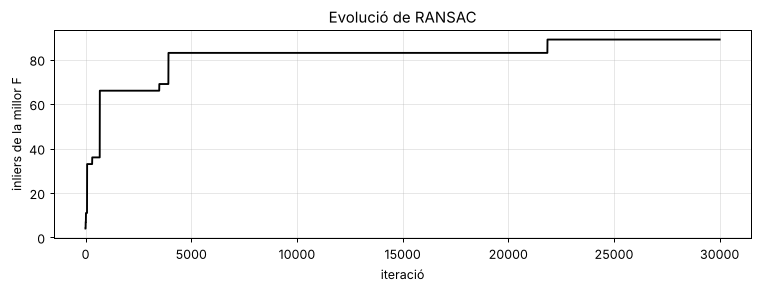

In [ ]:
INLIER_THRESHOLD_PX = 1.5
N_ITERATIONS = 30000


def ransac_fundamental(points_A, points_B, threshold_px, n_iterations, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    best_inliers = np.zeros(len(points_A), dtype=bool)
    history = []
    for iteration in range(n_iterations):
        sample = rng.choice(len(points_A), size=8, replace=False)              # 1. 8 random pairs
        F_candidate = fundamental_8point(points_A[sample], points_B[sample])  #    -> F
        distances = symmetric_epipolar_distance(F_candidate, points_A, points_B)  # 2. distance of ALL pairs
        inliers = distances < threshold_px                                     # 3. pairs accepted by this F
        if inliers.sum() > best_inliers.sum():                                 # 4. keep the best F
            best_inliers = inliers
            print(f"  intent {iteration:5d}: nova millor F, accepta {inliers.sum():4d} parelles de {len(points_A)}")
        history.append(best_inliers.sum())
    F_refined = fundamental_8point(points_A[best_inliers], points_B[best_inliers])
    final_inliers = symmetric_epipolar_distance(F_refined, points_A, points_B) < threshold_px
    return F_refined, final_inliers, history


F_ransac, ransac_inliers, ransac_history = ransac_fundamental(matches_A, matches_B, INLIER_THRESHOLD_PX, N_ITERATIONS)
print(f"\nResultat, després de recalcular F amb totes les parelles acceptades (pas 5): "
      f"{ransac_inliers.sum()} de {len(matches_A)} parelles ({ransac_inliers.mean():.0%})")

plt.figure(figsize=(10, 3)); plt.plot(ransac_history, color='black')
plt.xlabel("iteració"); plt.ylabel("inliers de la millor F"); plt.title("Evolució de RANSAC"); plt.grid(alpha=0.3); plt.show()

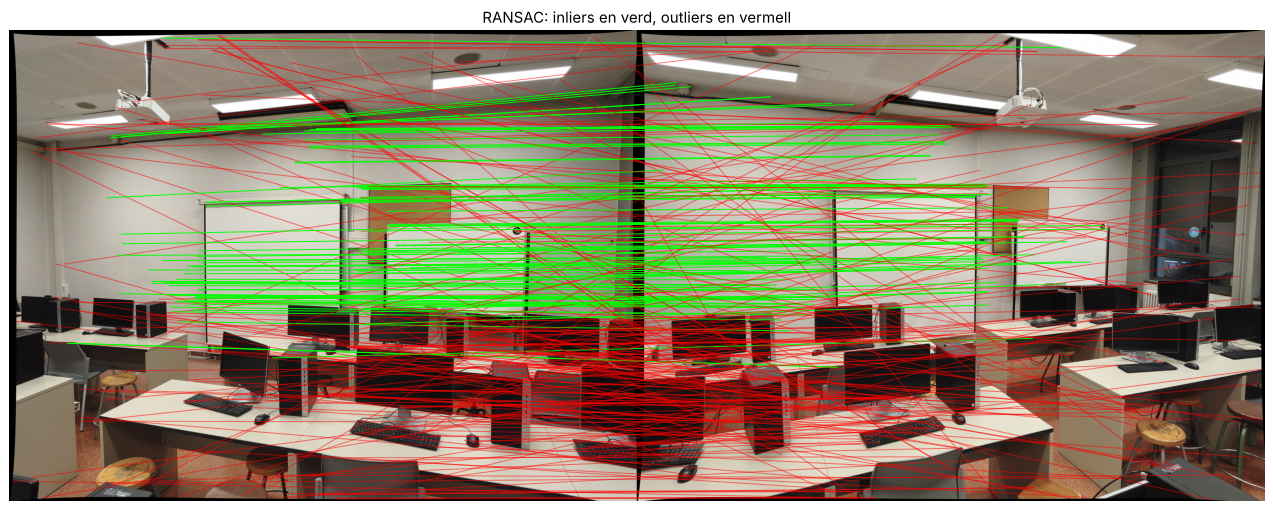

Inliers del nostre RANSAC: 108  ·  del filtre d'OpenCV (Part 2): 111  ·  en comú: 101


In [ ]:
canvas = np.hstack([undistorted_A, undistorted_B])
plt.figure(figsize=(18, 7)); plt.imshow(canvas)
for p, q, ok in zip(matches_A, matches_B, ransac_inliers):
    plt.plot([p[0], q[0] + image_width], [p[1], q[1]], '-', color='lime' if ok else 'red', lw=0.8, alpha=0.9 if ok else 0.5)
plt.title("RANSAC: inliers en verd, outliers en vermell"); plt.axis('off'); plt.show()

both = ransac_inliers & is_good
print(f"Inliers del nostre RANSAC: {ransac_inliers.sum()}  ·  del filtre d'OpenCV (Part 2): {is_good.sum()}  ·  en comú: {both.sum()}")

#### Exercicis

1. Canvia `INLIER_THRESHOLD_PX` a 0,5 px i a 5 px. Com canvia el nombre d'inliers i la distància mediana? Quin llindar és raonable i de què depèn?
2. Calcula amb la fórmula quantes iteracions calen si només el 20 % de les parelles són bones, amb mostres de 8 (F) i de 5 (E). Per què es diu que conèixer K "estalvia" iteracions?
3. Modifica `fundamental_8point` perquè **no normalitzi** els punts i repeteix l'apartat 2.6. Què passa amb la distància del punt de prova a la seva recta?

# PART 5 — Ampliació: imatges epipolars

Si deformem les dues fotos perquè **totes les rectes epipolars siguin horitzontals i a la mateixa altura**, l'homòleg de qualsevol punt queda **a la mateixa fila** de l'altra foto. És el **cas normal** de la fotogrametria (càmeres paral·leles), i aquestes imatges s'anomenen **imatges normalitzades** o **imatges epipolars**. És la base dels algorismes de núvols densos i de la visió estereoscòpica.

Es fa amb **dues homografies**, una per foto (el `warpPerspective` de S3), escollides perquè els epipols vagin a l'infinit en horitzontal. OpenCV les calcula a partir de F amb `cv2.stereoRectifyUncalibrated`.

Diferència de fila entre homòlegs (mediana): 0.63 px


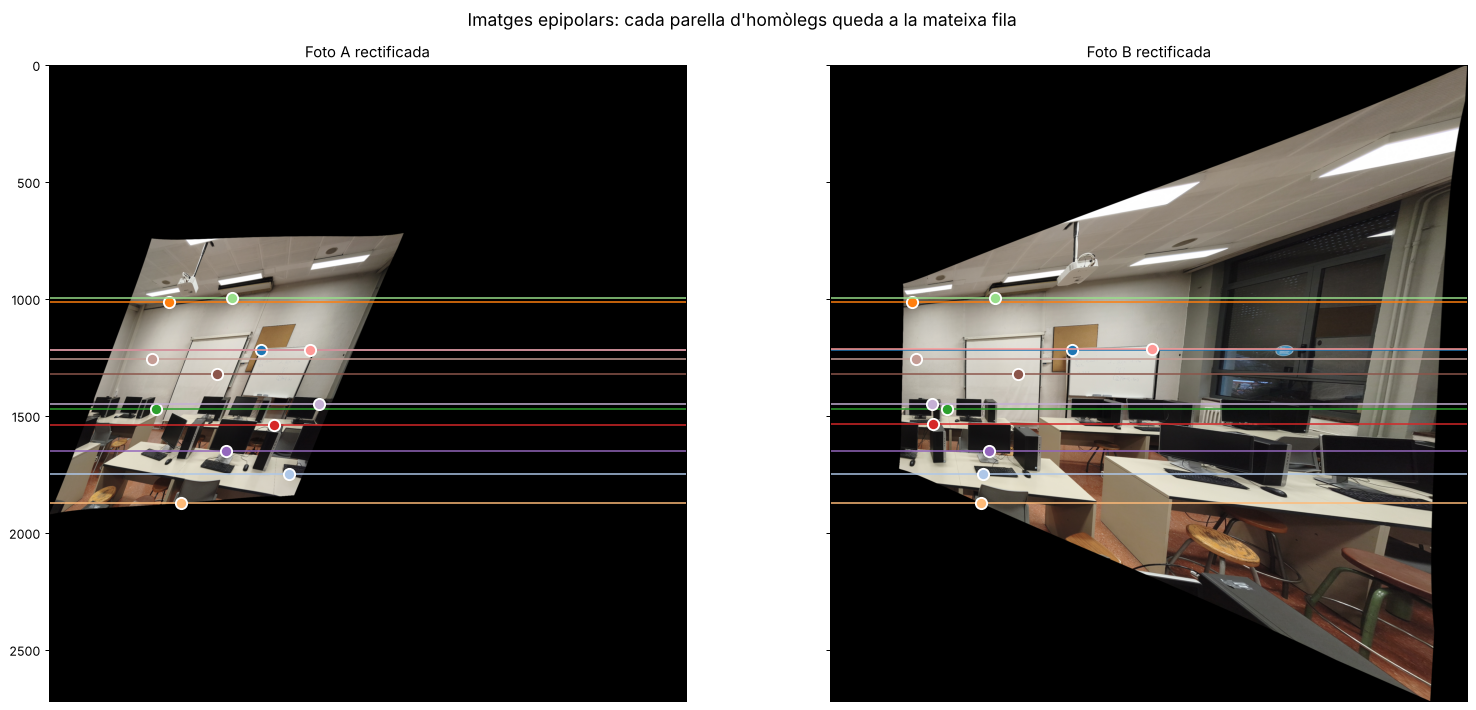

In [ ]:
def rectify_pair(F_matrix, points_A, points_B, image_1, image_2, display_scale=0.4):
    height, width = image_1.shape[:2]
    ok, H_1, H_2 = cv2.stereoRectifyUncalibrated(points_A, points_B, F_matrix, (width, height), threshold=INLIER_THRESHOLD_PX)
    corners = np.float32([[0, 0], [width, 0], [width, height], [0, height]]).reshape(-1, 1, 2)
    warped = np.vstack([cv2.perspectiveTransform(corners, H_1).reshape(-1, 2), cv2.perspectiveTransform(corners, H_2).reshape(-1, 2)])
    (u_min, v_min), (u_max, v_max) = warped.min(axis=0), warped.max(axis=0)
    to_canvas = np.array([[display_scale, 0, -u_min * display_scale], [0, display_scale, -v_min * display_scale], [0, 0, 1]])
    size = (int((u_max - u_min) * display_scale), int((v_max - v_min) * display_scale))
    rect_1 = cv2.warpPerspective(image_1, to_canvas @ H_1, size)
    rect_2 = cv2.warpPerspective(image_2, to_canvas @ H_2, size)
    content = (rect_1.sum(axis=2) > 0) | (rect_2.sum(axis=2) > 0)
    rows, cols = np.where(content.any(axis=1))[0], np.where(content.any(axis=0))[0]
    crop = np.array([[1, 0, -cols[0]], [0, 1, -rows[0]], [0, 0, 1]], dtype=float)
    return (rect_1[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1], rect_2[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1],
            crop @ to_canvas @ H_1, crop @ to_canvas @ H_2)


rectified_A, rectified_B, H_rect_A, H_rect_B = rectify_pair(F_all_good, good_A, good_B, undistorted_A, undistorted_B)
rect_A = cv2.perspectiveTransform(system_A.reshape(-1, 1, 2), H_rect_A).reshape(-1, 2)
rect_B = cv2.perspectiveTransform(system_B.reshape(-1, 1, 2), H_rect_B).reshape(-1, 2)
print(f"Diferència de fila entre homòlegs (mediana): {np.median(np.abs(rect_A[:, 1] - rect_B[:, 1])) / 0.4:.2f} px")

colors = plt.cm.tab20(np.arange(len(rect_A)) % 20)
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)
for ax, image, points, name in ((axes[0], rectified_A, rect_A, 'A'), (axes[1], rectified_B, rect_B, 'B')):
    ax.imshow(image)
    for p, color in zip(points, colors):
        ax.axhline(p[1], color=color, lw=1.2); ax.plot(*p, 'o', color=color, ms=9, mec='white', mew=1.5)
    ax.set_title(f"Foto {name} rectificada"); ax.set_xticks([])
fig.suptitle("Imatges epipolars: cada parella d'homòlegs queda a la mateixa fila", fontsize=14)
plt.tight_layout(); plt.show()

La foto B queda molt deformada perquè el seu epipol era a prop de la imatge (càmeres convergents). Com més paral·lels són els eixos de les dues càmeres, menys cal deformar les fotos: per això en fotogrametria es procura fotografiar amb **eixos gairebé paral·lels**.

**Propera sessió (S6):** de la matriu E en traurem el gir $R$ i la direcció de la base $\mathbf{t}$ (orientació relativa) i calcularem els primers **punts 3D**.